# DHB-XR: Features and Use-Cases Demo

This notebook demonstrates the main features and use-cases of **dhb_xr** (DHB Extended Representations) for SE(3) invariant trajectory encoding. Inspired by MATLAB Live Script workflows, we walk through:

1. **Constructing a 6-DOF trajectory** — position and orientation over time
2. **Encode and decode** — DHB-DR invariants and reconstruction
3. **SE(3) invariance** — invariants are unchanged under global rigid transforms
4. **DHB-DR vs DHB-QR** — Euler vs quaternion-based invariants
5. **DHB-TI (time-invariant)** — reparameterization by geometric progress
6. **Trajectory adaptation** — retargeting to a new initial pose
7. **Visualization** — 3D trajectories and invariant time series
8. **Optional: VLA tokenization** — discrete tokens for action representation

**Requirements:** `numpy`, `scipy`, `matplotlib`. Optional: `torch` for tokenization.

---
## Setup and imports

The first cell adds the repo **src** to `sys.path` if **dhb_xr** is not installed, so the notebook works when run from the repo (e.g. **pixi run notebook** from the dhb_xr root). If you get `ModuleNotFoundError: No module named 'dhb_xr'`, run this cell first and ensure the kernel's working directory is the **dhb_xr** repo root, or start Jupyter from the repo: `pixi run notebook`.

In [1]:
# Ensure dhb_xr is importable: add repo src to path if not installed (e.g. when using pixi run notebook)
import sys
from pathlib import Path

if "dhb_xr" not in sys.modules:
    def _find_src():
        for p in [Path.cwd()] + list(Path.cwd().parents):
            for root in [p, p / "dhb_xr"]:
                src = root / "src"
                if (root / "pyproject.toml").exists() and (src / "dhb_xr").exists():
                    return src
        return None
    src = _find_src()
    if src is not None and str(src) not in sys.path:
        sys.path.insert(0, str(src))

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from dhb_xr import encode_dhb_dr, decode_dhb_dr
from dhb_xr.core.types import DHBMethod
from dhb_xr.core import geometry as geom
from dhb_xr.encoder.dhb_ti import compute_progress, resample_by_progress, encode_dhb_dr_ti
from dhb_xr.visualization.plot import plot_se3_trajectory, plot_se3_trajectories, plot_invariants, draw_box, draw_frame
from dhb_xr.optimization.casadi_solver import generate_trajectory, HAS_CASADI

np.random.seed(42)
plt.rcParams['figure.figsize'] = (8, 5)

---
## 1. Construct a 6-DOF trajectory

We build a smooth SE(3) trajectory: **position** as a parametric curve (e.g. spiral or sinusoids) and **orientation** as time-varying Euler angles converted to quaternions (wxyz). This mimics typical motion data from robots or motion capture.

- **Position:** $x(t)$, $y(t)$, $z(t)$ — e.g. exponential + sinusoids
- **Orientation:** roll, pitch, yaw (Euler ZYX) → rotation matrix → quaternion (wxyz)

The result is `positions` (N×3) and `quaternions` (N×4) with **wxyz** convention (scalar first).

In [2]:
def build_demo_trajectory(n=80, dt=0.05):
    """Build a 6-DOF trajectory: position curve + orientation over time."""
    t = np.linspace(0, (n - 1) * dt, n)
    # Position: smooth curve (inspired by mainDHB.m)
    x = 0.1 * np.exp(t * 0.3)
    y = 0.5 + 0.3 * np.sin(t * 2)
    z = 0.2 * np.cos(t)
    positions = np.column_stack([x, y, z])
    # Orientation: roll, pitch, yaw (rad) -> quaternion wxyz
    roll = 0.3 * np.sin(t)
    pitch = 0.2 * np.cos(t * 1.5)
    yaw = 0.1 * t
    quaternions = np.array([
        geom.rot_to_quat(
            geom.euler_to_rot(np.array([roll[i], pitch[i], yaw[i]]))
        ) for i in range(n)
    ])
    return positions, quaternions

positions, quaternions = build_demo_trajectory(n=80)
print("Trajectory length:", len(positions))
print("Positions shape:", positions.shape, "| Quaternions shape:", quaternions.shape)
print("First position:", positions[0])
print("First quaternion (wxyz):", quaternions[0])

Trajectory length: 80
Positions shape: (80, 3) | Quaternions shape: (80, 4)
First position: [0.1 0.5 0.2]
First quaternion (wxyz): [0.99500417 0.         0.09983342 0.        ]


### Plot: 3D position trajectory

The curve shows the Cartesian path of the rigid body. Optionally we can draw orientation frames at sampled points.

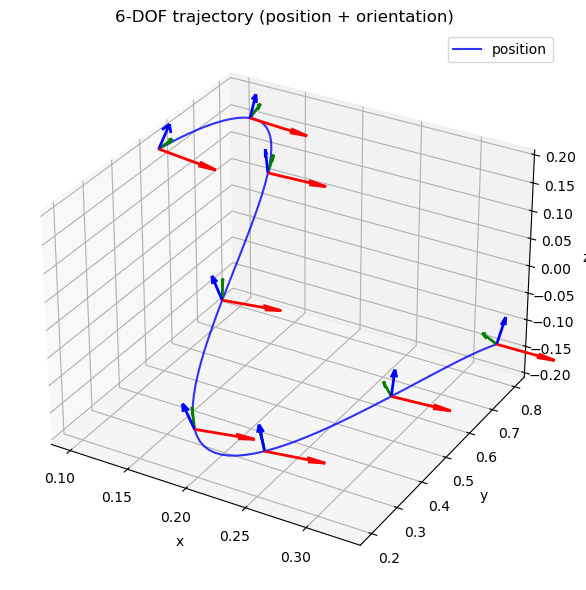

In [3]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
plot_se3_trajectory(positions, quaternions, ax=ax, title="6-DOF trajectory (position + orientation)", show_orientation=True)
ax.legend()
plt.tight_layout()
plt.show()

---
## 2. Encode and decode with DHB-DR

**DHB-DR** (double-reflection) computes *invariants* from the trajectory: for each step we get **linear invariants** (magnitude + Euler angles of the linear frame step) and **angular invariants** (magnitude + Euler angles of the angular step). These describe the motion in a way that is **independent of the global reference frame** (see next section).

- **Encode:** `encode_dhb_dr(positions, quaternions, ...)` → `linear_motion_invariants` (N′×4), `angular_motion_invariants` (N′×4), `initial_pose`
- **Decode:** `decode_dhb_dr(linear_inv, angular_inv, initial_pose, ...)` → `positions`, `quaternions` (reconstructed trajectory)

With default padding, the encoder output length N′ is slightly larger than N−2 so that decoding with `drop_padded=True` aligns with the original length convention.

In [4]:
out = encode_dhb_dr(
    positions, quaternions,
    method="pos",
    use_default_initial_frames=True,
    dhb_method=DHBMethod.DOUBLE_REFLECTION,
)
linear_inv = out["linear_motion_invariants"]
angular_inv = out["angular_motion_invariants"]
initial_pose = out["initial_pose"]

print("Encoded linear invariants shape:", linear_inv.shape)
print("Encoded angular invariants shape:", angular_inv.shape)
print("Initial pose position:", initial_pose["position"])

decoded = decode_dhb_dr(
    linear_inv, angular_inv, initial_pose,
    method="pos", dhb_method=DHBMethod.DOUBLE_REFLECTION, drop_padded=True,
)
pos_dec = decoded["positions"]
quat_dec = decoded["quaternions"]
print("Decoded positions shape:", pos_dec.shape)
print("Reconstruction error (position):", np.linalg.norm(pos_dec - positions[:len(pos_dec)]))
print("Reconstruction error (quat, geodesic approx):", np.mean([np.linalg.norm(geom.quat_relative_axis_angle(quat_dec[i], quaternions[i])) for i in range(len(quat_dec))]))

Encoded linear invariants shape: (82, 4)
Encoded angular invariants shape: (82, 4)
Initial pose position: [0.1 0.5 0.2]
Decoded positions shape: (80, 3)
Reconstruction error (position): 1.0307848268713797e-14
Reconstruction error (quat, geodesic approx): 2.723700601207636e-14


### Plot: Invariant time series

The **first column** of each invariant block is the **step magnitude** (translational and rotational); the remaining columns are orientation parameters (Euler angles in DHB-DR). These invariants fully describe the motion up to a global SE(3) frame.

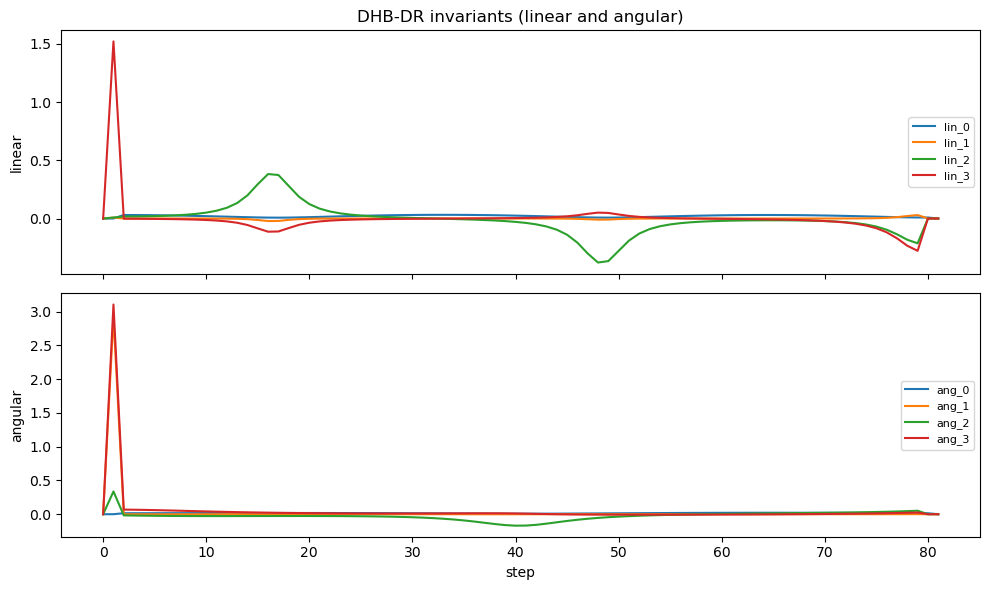

In [5]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
plot_invariants(linear_inv, angular_inv, ax=axes, title="DHB-DR invariants (linear and angular)")
plt.tight_layout()
plt.show()

---
## 3. SE(3) invariance

A key property of DHB invariants is **invariance to global SE(3) transforms**. If we apply the same rigid transformation (rotation $R$ and translation $t$) to every pose of the trajectory, the *invariant sequence* (magnitudes and relative frame structure) is **unchanged**.

So: *encode(original)* and *encode(transformed)* yield the same linear/angular invariant **magnitudes** (first column). This is useful for comparing motions regardless of where they were performed or how the world frame was defined.

In [6]:
def apply_se3(positions, quaternions, R, t):
    """Apply global SE(3): p' = R p + t, q' = R * q (rotation composition)."""
    p_new = (R @ positions.T).T + t
    q_new = np.array([geom.rot_to_quat(R @ geom.quat_to_rot(q)) for q in quaternions])
    return p_new, q_new

# Random SE(3) transform
axis = np.random.randn(3)
axis /= np.linalg.norm(axis)
R = geom.axis_angle_to_rot(axis * 0.5)
t_vec = np.array([0.2, -0.1, 0.15])
positions_tf, quaternions_tf = apply_se3(positions, quaternions, R, t_vec)

out_orig = encode_dhb_dr(positions, quaternions, method="pos", use_default_initial_frames=True, dhb_method=DHBMethod.DOUBLE_REFLECTION)
out_tf   = encode_dhb_dr(positions_tf, quaternions_tf, method="pos", use_default_initial_frames=True, dhb_method=DHBMethod.DOUBLE_REFLECTION)

lin_orig = out_orig["linear_motion_invariants"]
ang_orig = out_orig["angular_motion_invariants"]
lin_tf   = out_tf["linear_motion_invariants"]
ang_tf   = out_tf["angular_motion_invariants"]

match_lin = np.allclose(lin_orig[:, 0], lin_tf[:, 0])
match_ang = np.allclose(ang_orig[:, 0], ang_tf[:, 0])
print("Linear  magnitude invariant (first column) match:", match_lin)
print("Angular magnitude invariant (first column) match:", match_ang)
print("Max diff linear  mag:", np.max(np.abs(lin_orig[:, 0] - lin_tf[:, 0])))
print("Max diff angular mag:", np.max(np.abs(ang_orig[:, 0] - ang_tf[:, 0])))

Linear  magnitude invariant (first column) match: True
Angular magnitude invariant (first column) match: True
Max diff linear  mag: 1.5265566588595902e-16
Max diff angular mag: 1.5785983631388945e-16


### Plot: Original vs transformed trajectory

The two trajectories differ by a global rigid transform; their DHB invariant magnitudes are the same.

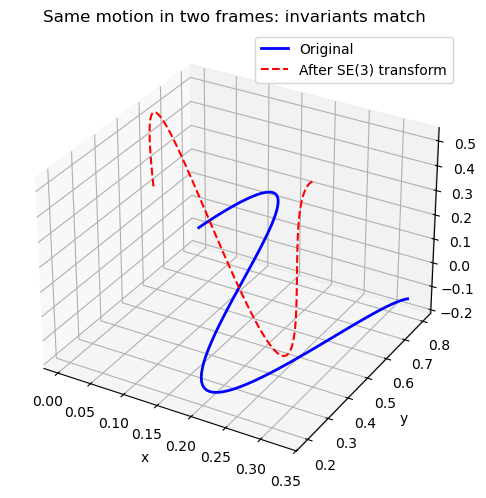

In [7]:
fig = plt.figure(figsize=(9, 5))
ax = fig.add_subplot(111, projection='3d')
ax.plot(positions[:, 0], positions[:, 1], positions[:, 2], 'b-', label='Original', linewidth=2)
ax.plot(positions_tf[:, 0], positions_tf[:, 1], positions_tf[:, 2], 'r--', label='After SE(3) transform', linewidth=1.5)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title('Same motion in two frames: invariants match')
ax.legend()
plt.tight_layout()
plt.show()

---
## 4. DHB-DR vs DHB-QR

- **DHB-DR** uses **Euler angles** for the relative orientation at each step → 4 values per component (magnitude + 3 Euler). Can suffer from gimbal lock.
- **DHB-QR** uses **quaternions** for the relative rotation → 5 values per component (magnitude + 4D quaternion, with unit norm). Singularity-free and convenient for geodesic losses.

Same trajectory encoded with both yields different *shapes* (e.g. linear invariants (N,4) vs (N,5)); the *information* is equivalent up to representation.

In [8]:
from dhb_xr.encoder.dhb_dr import encode_dhb_dr
from dhb_xr.encoder.dhb_qr import encode_dhb_qr

out_dr = encode_dhb_dr(positions, quaternions, method="pos", use_default_initial_frames=True, dhb_method=DHBMethod.DOUBLE_REFLECTION)
out_qr = encode_dhb_qr(positions, quaternions, method="pos", use_default_initial_frames=True)

print("DHB-DR linear invariants shape:", out_dr["linear_motion_invariants"].shape)
print("DHB-QR linear invariants shape:", out_qr["linear_motion_invariants"].shape)
print("DHB-DR: 4 values per step (magnitude + Euler). DHB-QR: 5 values per step (magnitude + quat).")

DHB-DR linear invariants shape: (82, 4)
DHB-QR linear invariants shape: (82, 5)
DHB-DR: 4 values per step (magnitude + Euler). DHB-QR: 5 values per step (magnitude + quat).


---
## 5. DHB-TI: Time-invariant reparameterization

### The Problem with Time-Based Invariants

Standard DHB-DR/DHB-QR invariants depend on **temporal sampling**:
- **Same motion executed faster** → different invariants (higher magnitude)
- **Same motion with fewer samples** → different invariant sequence length

This is problematic for:
- **Imitation learning**: Demos recorded at different speeds should be treated as equivalent
- **Motion retrieval**: Finding similar motions regardless of execution speed
- **Robustness**: Small timing variations shouldn't change the motion representation

### The Solution: Geometric Progress

**DHB-TI** reparameterizes the trajectory by a **geometric progress variable** instead of time:

| Progress Type | Formula | Best For |
|---------------|---------|----------|
| **Translation** | Cumulative arc-length ∑‖Δp‖ | Position-dominated motions |
| **Angular** | Cumulative rotation ∑‖Δr‖ | Rotation-dominated (in-place turns) |
| **Hybrid** | α·translation + (1-α)·angular | General SE(3) motions |

After reparameterization, poses are **resampled at uniform progress knots**, making invariants:
- ✓ Independent of execution speed
- ✓ Independent of original sampling rate
- ✓ Same length (M samples) for any input

In [9]:
from dhb_xr.encoder.dhb_ti import compute_progress, resample_by_progress, encode_dhb_dr_ti

# Create the SAME spatial trajectory executed at 3 different speeds
def create_trajectory_at_speed(speed_factor, n_samples):
    """Create spiral trajectory with given speed factor and sampling."""
    # Spatial parameter (0 to 1 along the path)
    s = np.linspace(0, 1, n_samples)
    
    # Positions: spiral in 3D
    radius = 0.3 + 0.2 * s
    angle = s * 4 * np.pi  # 2 full rotations
    pos = np.column_stack([
        radius * np.cos(angle),
        radius * np.sin(angle),
        s * 0.5  # rising spiral
    ])
    
    # Orientations: rotate with the spiral
    quats = np.array([
        geom.rot_to_quat(geom.euler_to_rot(np.array([0.2 * s[i], 0.3 * s[i], angle[i] * 0.5])))
        for i in range(n_samples)
    ])
    
    return pos, quats

# Three versions of the same motion:
# 1. Slow execution (100 samples)
# 2. Normal execution (50 samples)  
# 3. Fast execution (25 samples)
pos_slow, quat_slow = create_trajectory_at_speed(1.0, 100)
pos_normal, quat_normal = create_trajectory_at_speed(1.0, 50)
pos_fast, quat_fast = create_trajectory_at_speed(1.0, 25)

print("Created 3 versions of the same trajectory:")
print(f"  Slow:   {len(pos_slow)} samples (dense sampling)")
print(f"  Normal: {len(pos_normal)} samples")
print(f"  Fast:   {len(pos_fast)} samples (sparse sampling)")

Created 3 versions of the same trajectory:
  Slow:   100 samples (dense sampling)
  Normal: 50 samples
  Fast:   25 samples (sparse sampling)


In [38]:
# Encode with standard DHB-DR (time-based) - DIFFERENT results!
init_slow = {"position": pos_slow[0], "quaternion": quat_slow[0]}
init_normal = {"position": pos_normal[0], "quaternion": quat_normal[0]}
init_fast = {"position": pos_fast[0], "quaternion": quat_fast[0]}

dr_slow = encode_dhb_dr(pos_slow, quat_slow, init_pose=init_slow)
dr_normal = encode_dhb_dr(pos_normal, quat_normal, init_pose=init_normal)
dr_fast = encode_dhb_dr(pos_fast, quat_fast, init_pose=init_fast)

# Encode with DHB-TI (time-invariant) - SAME results!
M = 30  # Resample all to same length
ti_slow = encode_dhb_dr_ti(pos_slow, quat_slow, M=M, init_pose=init_slow)
ti_normal = encode_dhb_dr_ti(pos_normal, quat_normal, M=M, init_pose=init_normal)
ti_fast = encode_dhb_dr_ti(pos_fast, quat_fast, M=M, init_pose=init_fast)

print("=== Standard DHB-DR (time-based) ===")
print(f"  Slow invariants:   shape {dr_slow['linear_motion_invariants'].shape}")
print(f"  Normal invariants: shape {dr_normal['linear_motion_invariants'].shape}")
print(f"  Fast invariants:   shape {dr_fast['linear_motion_invariants'].shape}")
print("  → Different lengths! Cannot directly compare.")

print("\n=== DHB-TI (time-invariant) ===")
print(f"  Slow invariants:   shape {ti_slow['linear_motion_invariants'].shape}")
print(f"  Normal invariants: shape {ti_normal['linear_motion_invariants'].shape}")
print(f"  Fast invariants:   shape {ti_fast['linear_motion_invariants'].shape}")
print("  → Same length! Can directly compare.")

=== Standard DHB-DR (time-based) ===
  Slow invariants:   shape (102, 4)
  Normal invariants: shape (52, 4)
  Fast invariants:   shape (27, 4)
  → Different lengths! Cannot directly compare.

=== DHB-TI (time-invariant) ===
  Slow invariants:   shape (32, 4)
  Normal invariants: shape (32, 4)
  Fast invariants:   shape (32, 4)
  → Same length! Can directly compare.


In [39]:
# Compute similarity between invariant sequences
def invariant_distance(inv1, inv2):
    """MSE between two invariant sequences (must have same length)."""
    lin1 = np.concatenate([inv1['linear_motion_invariants'], inv1['angular_motion_invariants']], axis=1)
    lin2 = np.concatenate([inv2['linear_motion_invariants'], inv2['angular_motion_invariants']], axis=1)
    return np.mean((lin1 - lin2) ** 2)

# DHB-TI distances (should be ~0)
dist_ti_slow_normal = invariant_distance(ti_slow, ti_normal)
dist_ti_slow_fast = invariant_distance(ti_slow, ti_fast)
dist_ti_normal_fast = invariant_distance(ti_normal, ti_fast)

print("=== DHB-TI Invariant Distances (same trajectory, different sampling) ===")
print(f"  Slow vs Normal:  {dist_ti_slow_normal:.6f}")
print(f"  Slow vs Fast:    {dist_ti_slow_fast:.6f}")
print(f"  Normal vs Fast:  {dist_ti_normal_fast:.6f}")
print("  → Near-zero! DHB-TI recognizes these as the SAME motion.")

# For comparison: what if we just truncated time-based invariants?
min_len = min(len(dr_slow['linear_motion_invariants']), 
              len(dr_normal['linear_motion_invariants']),
              len(dr_fast['linear_motion_invariants']))
truncated_slow = {'linear_motion_invariants': dr_slow['linear_motion_invariants'][:min_len],
                  'angular_motion_invariants': dr_slow['angular_motion_invariants'][:min_len]}
truncated_fast = {'linear_motion_invariants': dr_fast['linear_motion_invariants'][:min_len],
                  'angular_motion_invariants': dr_fast['angular_motion_invariants'][:min_len]}
dist_dr_truncated = invariant_distance(truncated_slow, truncated_fast)
print(f"\n  (Naive truncated DHB-DR distance: {dist_dr_truncated:.6f} — much higher!)")

=== DHB-TI Invariant Distances (same trajectory, different sampling) ===
  Slow vs Normal:  0.000000
  Slow vs Fast:    0.000001
  Normal vs Fast:  0.000001
  → Near-zero! DHB-TI recognizes these as the SAME motion.

  (Naive truncated DHB-DR distance: 0.027405 — much higher!)


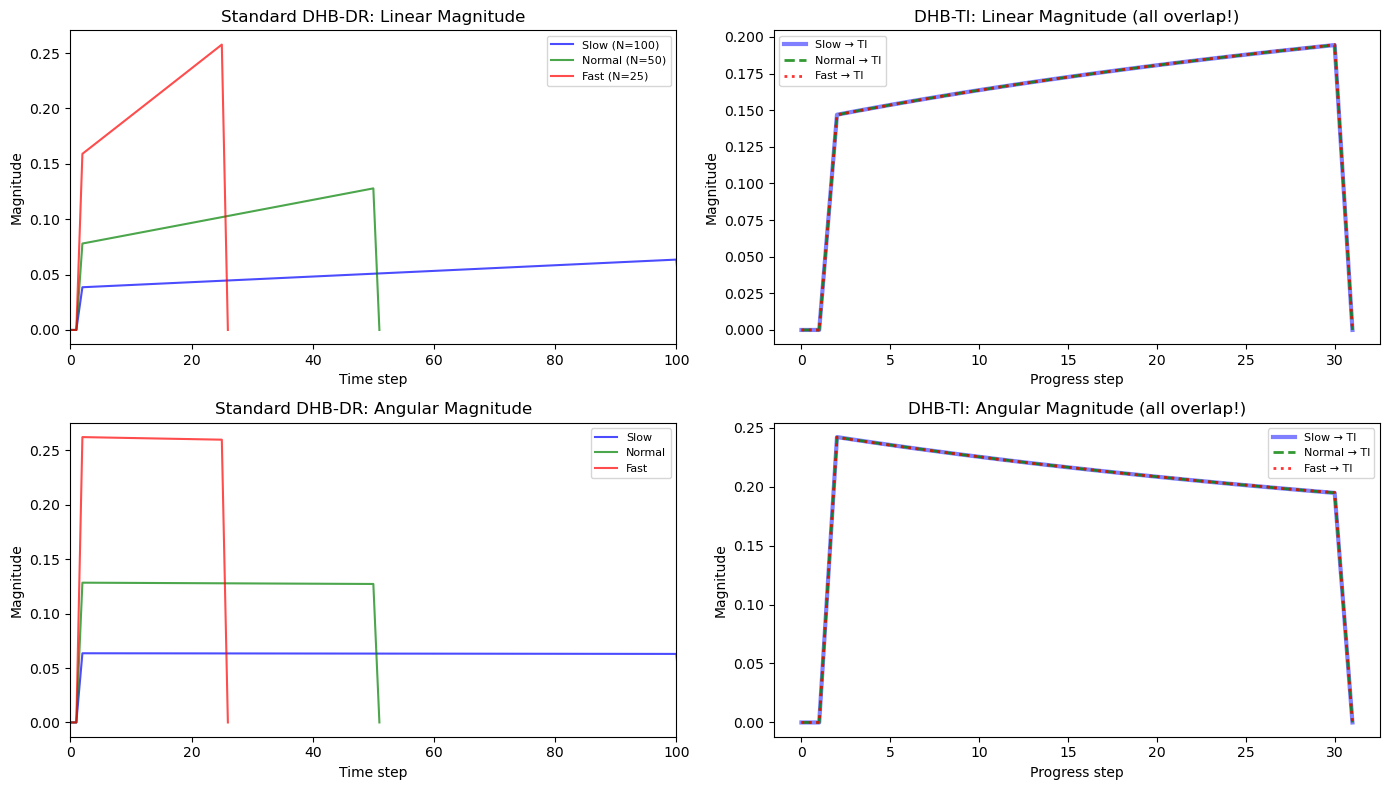

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Plot 1: Standard DHB-DR invariants (different lengths)
ax = axes[0, 0]
ax.plot(dr_slow['linear_motion_invariants'][:, 0], 'b-', alpha=0.7, label=f'Slow (N={len(pos_slow)})')
ax.plot(dr_normal['linear_motion_invariants'][:, 0], 'g-', alpha=0.7, label=f'Normal (N={len(pos_normal)})')
ax.plot(dr_fast['linear_motion_invariants'][:, 0], 'r-', alpha=0.7, label=f'Fast (N={len(pos_fast)})')
ax.set_title('Standard DHB-DR: Linear Magnitude')
ax.set_xlabel('Time step')
ax.set_ylabel('Magnitude')
ax.legend(fontsize=8)
ax.set_xlim(0, 100)

# Plot 2: DHB-TI invariants (all same length, overlapping)
ax = axes[0, 1]
ax.plot(ti_slow['linear_motion_invariants'][:, 0], 'b-', linewidth=3, alpha=0.5, label='Slow → TI')
ax.plot(ti_normal['linear_motion_invariants'][:, 0], 'g--', linewidth=2, alpha=0.8, label='Normal → TI')
ax.plot(ti_fast['linear_motion_invariants'][:, 0], 'r:', linewidth=2, alpha=0.8, label='Fast → TI')
ax.set_title('DHB-TI: Linear Magnitude (all overlap!)')
ax.set_xlabel('Progress step')
ax.set_ylabel('Magnitude')
ax.legend(fontsize=8)

# Plot 3: Angular invariants comparison
ax = axes[1, 0]
ax.plot(dr_slow['angular_motion_invariants'][:, 0], 'b-', alpha=0.7, label='Slow')
ax.plot(dr_normal['angular_motion_invariants'][:, 0], 'g-', alpha=0.7, label='Normal')
ax.plot(dr_fast['angular_motion_invariants'][:, 0], 'r-', alpha=0.7, label='Fast')
ax.set_title('Standard DHB-DR: Angular Magnitude')
ax.set_xlabel('Time step')
ax.set_ylabel('Magnitude')
ax.legend(fontsize=8)
ax.set_xlim(0, 100)

# Plot 4: DHB-TI angular
ax = axes[1, 1]
ax.plot(ti_slow['angular_motion_invariants'][:, 0], 'b-', linewidth=3, alpha=0.5, label='Slow → TI')
ax.plot(ti_normal['angular_motion_invariants'][:, 0], 'g--', linewidth=2, alpha=0.8, label='Normal → TI')
ax.plot(ti_fast['angular_motion_invariants'][:, 0], 'r:', linewidth=2, alpha=0.8, label='Fast → TI')
ax.set_title('DHB-TI: Angular Magnitude (all overlap!)')
ax.set_xlabel('Progress step')
ax.set_ylabel('Magnitude')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

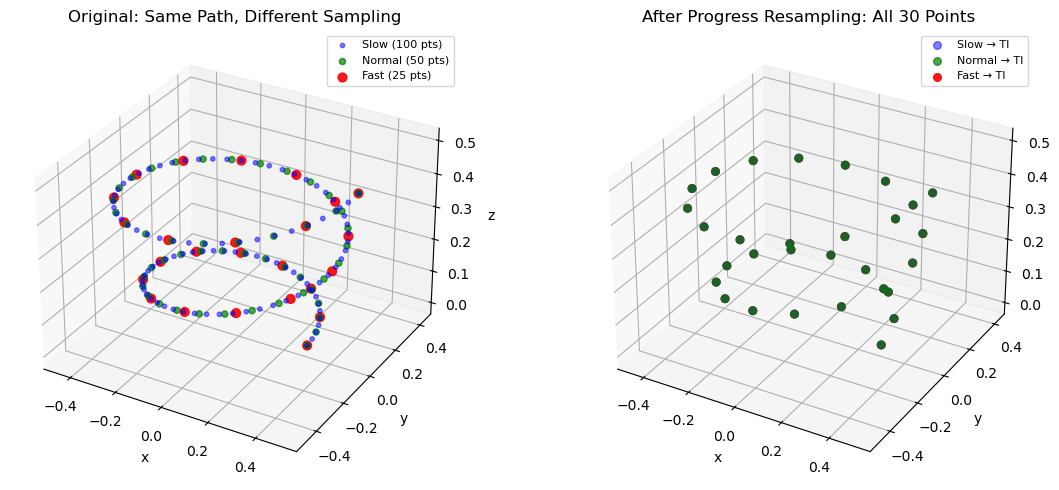

Points now lie at the SAME locations along the path, regardless of original sampling.


In [41]:
fig = plt.figure(figsize=(12, 5))

# Original trajectories (different sampling)
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(pos_slow[:, 0], pos_slow[:, 1], pos_slow[:, 2], c='blue', s=10, alpha=0.5, label=f'Slow ({len(pos_slow)} pts)')
ax1.scatter(pos_normal[:, 0], pos_normal[:, 1], pos_normal[:, 2], c='green', s=20, alpha=0.7, label=f'Normal ({len(pos_normal)} pts)')
ax1.scatter(pos_fast[:, 0], pos_fast[:, 1], pos_fast[:, 2], c='red', s=40, alpha=0.9, label=f'Fast ({len(pos_fast)} pts)')
ax1.set_title('Original: Same Path, Different Sampling')
ax1.legend(fontsize=8)
ax1.set_xlabel('x'); ax1.set_ylabel('y'); ax1.set_zlabel('z')

# Resampled trajectories (all M points)
pos_ti_slow, _ = resample_by_progress(pos_slow, quat_slow, M=M)
pos_ti_normal, _ = resample_by_progress(pos_normal, quat_normal, M=M)
pos_ti_fast, _ = resample_by_progress(pos_fast, quat_fast, M=M)

ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(pos_ti_slow[:, 0], pos_ti_slow[:, 1], pos_ti_slow[:, 2], c='blue', s=30, alpha=0.5, label='Slow → TI')
ax2.scatter(pos_ti_normal[:, 0], pos_ti_normal[:, 1], pos_ti_normal[:, 2], c='green', s=30, alpha=0.7, label='Normal → TI')
ax2.scatter(pos_ti_fast[:, 0], pos_ti_fast[:, 1], pos_ti_fast[:, 2], c='red', s=30, alpha=0.9, label='Fast → TI')
ax2.set_title(f'After Progress Resampling: All {M} Points')
ax2.legend(fontsize=8)
ax2.set_xlabel('x'); ax2.set_ylabel('y'); ax2.set_zlabel('z')

plt.tight_layout()
plt.show()

print("Points now lie at the SAME locations along the path, regardless of original sampling.")

### Use Case: Motion Retrieval Demo

DHB-TI enables **robust motion matching** even when demonstrations have:
- Different execution speeds (slow vs fast)
- Different starting positions
- Different sampling rates

This is powerful for:
- **Motion primitive databases**: Match user demonstrations to known skills
- **Cross-embodiment transfer**: Same motion pattern, different robots
- **Imitation learning**: Retrieve similar demonstrations for policy training

Let's build a toy motion database and demonstrate invariant-based retrieval!

In [39]:
# Motion Retrieval Demo: Build a database of motion primitives
from dhb_xr.encoder.dhb_ti import encode_dhb_dr_ti, compute_progress

def generate_motion(motion_type, n_points=50, speed=1.0, offset=np.array([0, 0, 0])):
    """
    Generate different motion types with variable speed and position.
    
    Args:
        motion_type: 'circle', 'helix', 'line', 'arc', 'figure8'
        n_points: Number of samples (simulates different sampling rates)
        speed: Affects trajectory length (simulates execution speed)
        offset: Starting position offset
    """
    t = np.linspace(0, 2 * np.pi / speed, n_points)
    
    if motion_type == 'circle':
        # Circular motion in XY plane
        pos = np.column_stack([
            0.3 * np.cos(t * speed),
            0.3 * np.sin(t * speed),
            np.zeros(n_points)
        ])
    elif motion_type == 'helix':
        # Helical motion (spiral upward)
        pos = np.column_stack([
            0.2 * np.cos(t * speed),
            0.2 * np.sin(t * speed),
            0.1 * t * speed / (2 * np.pi)
        ])
    elif motion_type == 'line':
        # Straight line motion
        pos = np.column_stack([
            0.3 * t * speed / (2 * np.pi),
            0.1 * t * speed / (2 * np.pi),
            0.05 * t * speed / (2 * np.pi)
        ])
    elif motion_type == 'arc':
        # Arc motion (partial circle)
        theta = t * speed * 0.7  # 70% of full circle
        pos = np.column_stack([
            0.25 * np.cos(theta),
            0.25 * np.sin(theta),
            0.02 * np.sin(theta * 2)
        ])
    elif motion_type == 'figure8':
        # Figure-8 motion (Lissajous curve)
        pos = np.column_stack([
            0.2 * np.sin(t * speed),
            0.15 * np.sin(2 * t * speed),
            0.05 * np.cos(t * speed)
        ])
    else:
        raise ValueError(f'Unknown motion type: {motion_type}')
    
    # Apply offset
    pos = pos + offset
    
    # Identity quaternion (no rotation)
    quat = np.tile([1.0, 0.0, 0.0, 0.0], (n_points, 1))
    
    return pos, quat

# Build motion database with variations
motion_types = ['circle', 'helix', 'line', 'arc', 'figure8']
M = 30  # Uniform resampling for DHB-TI

motion_db = {}
np.random.seed(123)

for mtype in motion_types:
    for variant in ['slow', 'normal', 'fast']:
        # Vary speed and sampling
        speed = {'slow': 0.5, 'normal': 1.0, 'fast': 2.0}[variant]
        n_pts = {'slow': 100, 'normal': 50, 'fast': 25}[variant]
        offset = np.random.randn(3) * 0.1  # Random position offset
        
        pos, quat = generate_motion(mtype, n_points=n_pts, speed=speed, offset=offset)
        
        # Encode with DHB-TI (time-invariant)
        result = encode_dhb_dr_ti(pos, quat, M=M, progress_kind='translation')
        invariants = np.hstack([
            result['linear_motion_invariants'],
            result['angular_motion_invariants']
        ])
        
        key = f'{mtype}_{variant}'
        motion_db[key] = {
            'type': mtype,
            'variant': variant,
            'positions': pos,
            'invariants': invariants,
            'n_original': n_pts,
        }

print(f'Motion database: {len(motion_db)} entries')
print(f'Motion types: {motion_types}')
print(f'Variants per type: slow, normal, fast')
print(f'Invariant shape: {invariants.shape} (M={M} uniform samples)')

Motion database: 15 entries
Motion types: ['circle', 'helix', 'line', 'arc', 'figure8']
Variants per type: slow, normal, fast
Invariant shape: (32, 8) (M=30 uniform samples)


In [40]:
# Define similarity metrics for motion retrieval

def invariant_distance(inv1, inv2):
    """Compute distance between two invariant sequences (Euclidean)."""
    return np.linalg.norm(inv1 - inv2)

def position_distance(pos1, pos2):
    """Compute distance between positions (needs alignment first)."""
    # Simple: Compare endpoints and midpoint
    if len(pos1) != len(pos2):
        # Resample to same length
        from scipy.interpolate import interp1d
        t1 = np.linspace(0, 1, len(pos1))
        t2 = np.linspace(0, 1, len(pos2))
        t_common = np.linspace(0, 1, 50)
        pos1_rs = interp1d(t1, pos1, axis=0)(t_common)
        pos2_rs = interp1d(t2, pos2, axis=0)(t_common)
    else:
        pos1_rs, pos2_rs = pos1, pos2
    return np.linalg.norm(pos1_rs - pos2_rs)

def retrieve_motion(query_inv, db, top_k=3):
    """Find most similar motions in database."""
    distances = []
    for key, entry in db.items():
        dist = invariant_distance(query_inv, entry['invariants'])
        distances.append((key, dist, entry['type']))
    
    distances.sort(key=lambda x: x[1])
    return distances[:top_k]

print('Similarity functions defined!')
print('  - invariant_distance: L2 norm on DHB-TI invariants')
print('  - position_distance: L2 norm on resampled positions')
print('  - retrieve_motion: Top-K nearest neighbor search')

Similarity functions defined!
  - invariant_distance: L2 norm on DHB-TI invariants
  - position_distance: L2 norm on resampled positions
  - retrieve_motion: Top-K nearest neighbor search


In [41]:
# Motion Retrieval: Query with new motions and find matches

# Generate query motions (different speed/position than database)
queries = [
    ('circle', 80, 0.7, np.array([0.5, 0.3, 0.1])),   # Circle at different position/speed
    ('helix', 35, 1.5, np.array([-0.2, 0.1, 0.0])),   # Helix, different sampling
    ('line', 60, 0.8, np.array([0.0, 0.5, 0.2])),     # Line, different offset
    ('figure8', 45, 1.2, np.array([0.1, -0.1, 0.0])), # Figure-8
]

print('=== Motion Retrieval Results ===')
print()

results = []
for gt_type, n_pts, speed, offset in queries:
    # Generate query
    q_pos, q_quat = generate_motion(gt_type, n_points=n_pts, speed=speed, offset=offset)
    
    # Encode query with DHB-TI
    q_result = encode_dhb_dr_ti(q_pos, q_quat, M=M, progress_kind='translation')
    q_inv = np.hstack([q_result['linear_motion_invariants'], q_result['angular_motion_invariants']])
    
    # Retrieve
    matches = retrieve_motion(q_inv, motion_db, top_k=3)
    
    # Check if correct type is in top-1
    top1_correct = matches[0][2] == gt_type
    top3_correct = any(m[2] == gt_type for m in matches)
    
    print(f'Query: {gt_type} (n={n_pts}, speed={speed})')
    print(f'  Top-3 matches:')
    for rank, (key, dist, mtype) in enumerate(matches, 1):
        marker = '✓' if mtype == gt_type else ' '
        print(f'    {rank}. {key:20s} (dist={dist:.4f}) {marker}')
    print(f'  Top-1 correct: {top1_correct}, Top-3 correct: {top3_correct}')
    print()
    
    results.append({
        'gt_type': gt_type,
        'query_pos': q_pos,
        'query_inv': q_inv,
        'matches': matches,
        'top1_correct': top1_correct,
    })

# Summary
top1_acc = sum(r['top1_correct'] for r in results) / len(results)
print(f'=== Summary: Top-1 Accuracy = {top1_acc*100:.0f}% ===')

=== Motion Retrieval Results ===

Query: circle (n=80, speed=0.7)
  Top-3 matches:
    1. circle_slow          (dist=0.0000) ✓
    2. circle_normal        (dist=0.0000) ✓
    3. circle_fast          (dist=0.0011) ✓
  Top-1 correct: True, Top-3 correct: True

Query: helix (n=35, speed=1.5)
  Top-3 matches:
    1. helix_normal         (dist=0.0001) ✓
    2. helix_slow           (dist=0.0001) ✓
    3. helix_fast           (dist=0.0013) ✓
  Top-1 correct: True, Top-3 correct: True

Query: line (n=60, speed=0.8)
  Top-3 matches:
    1. line_slow            (dist=0.0000) ✓
    2. line_normal          (dist=0.0000) ✓
    3. line_fast            (dist=0.0000) ✓
  Top-1 correct: True, Top-3 correct: True

Query: figure8 (n=45, speed=1.2)
  Top-3 matches:
    1. figure8_normal       (dist=0.0047) ✓
    2. figure8_slow         (dist=0.0074) ✓
    3. figure8_fast         (dist=0.1656) ✓
  Top-1 correct: True, Top-3 correct: True

=== Summary: Top-1 Accuracy = 100% ===


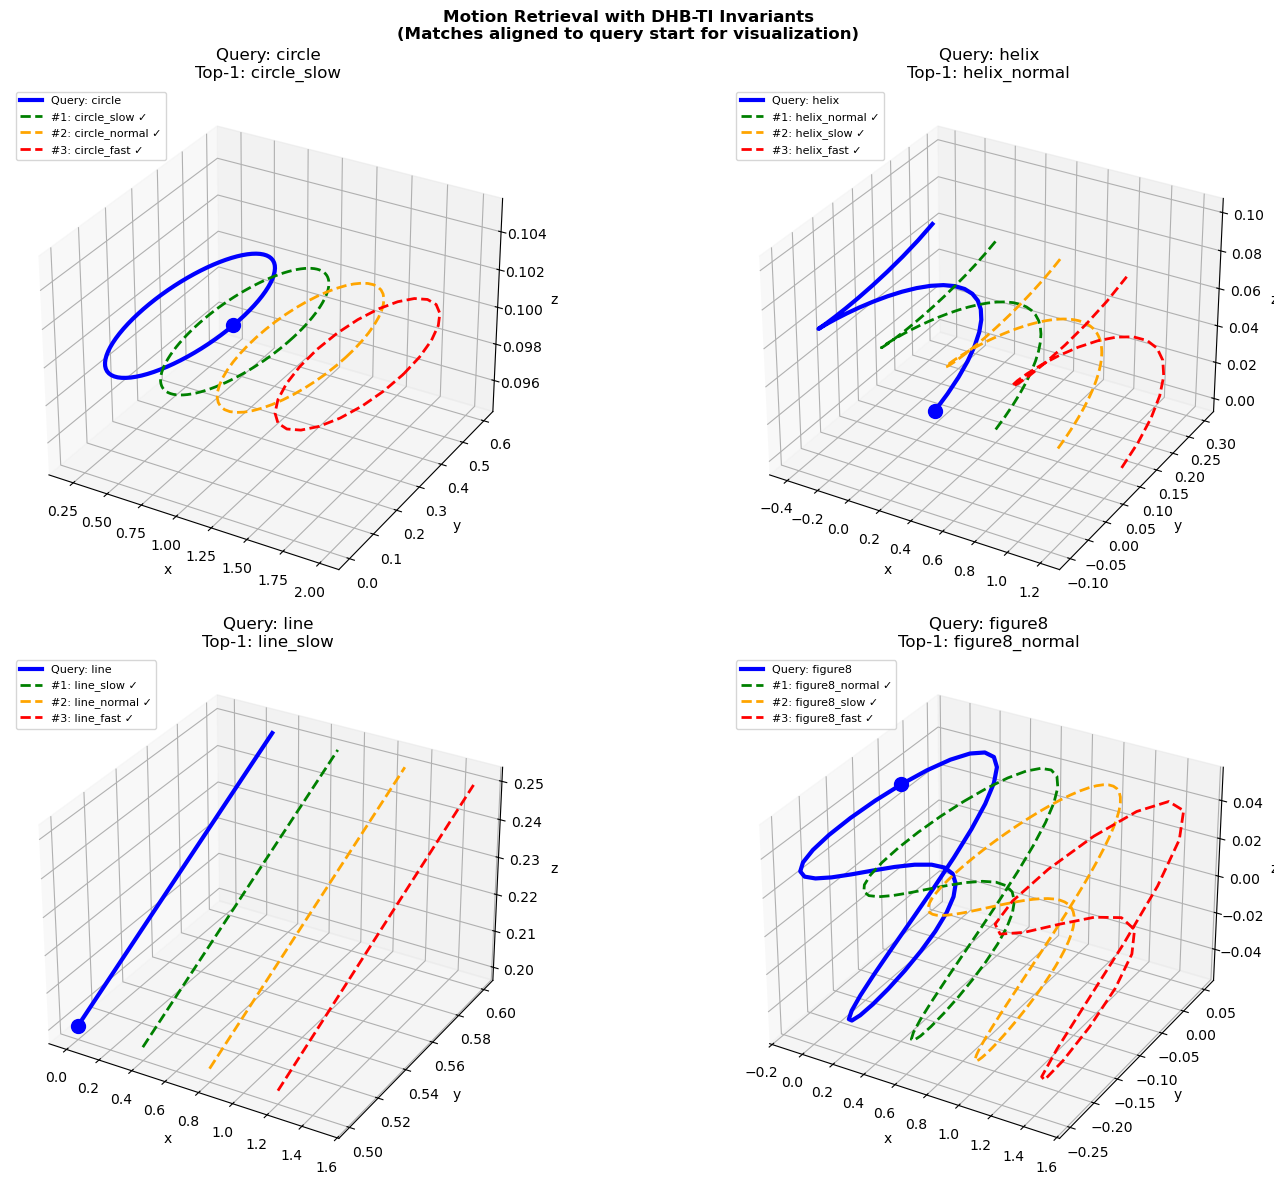


Key insight: Despite different speeds, sampling rates, and positions,
DHB-TI invariants correctly identify the underlying motion pattern!


In [42]:
# Visualize retrieval results
fig = plt.figure(figsize=(16, 12))

for i, res in enumerate(results):
    gt_type = res['gt_type']
    q_pos = res['query_pos']
    matches = res['matches']
    
    # Plot query and top-3 matches
    ax = fig.add_subplot(2, 2, i+1, projection='3d')
    
    # Query (thick blue)
    ax.plot(q_pos[:, 0], q_pos[:, 1], q_pos[:, 2], 'b-', linewidth=3, label=f'Query: {gt_type}')
    ax.scatter(q_pos[0, 0], q_pos[0, 1], q_pos[0, 2], color='blue', s=100, marker='o')
    
    # Top-3 matches
    colors = ['green', 'orange', 'red']
    for j, (key, dist, mtype) in enumerate(matches):
        match_pos = motion_db[key]['positions']
        # Shift for visibility
        shift = np.array([0.4 * (j + 1), 0, 0])
        match_pos_shifted = match_pos - match_pos[0] + q_pos[0] + shift
        
        marker = '✓' if mtype == gt_type else '✗'
        ax.plot(match_pos_shifted[:, 0], match_pos_shifted[:, 1], match_pos_shifted[:, 2], 
                color=colors[j], linewidth=2, linestyle='--',
                label=f'#{j+1}: {key} {marker}')
    
    ax.set_title(f'Query: {gt_type}\nTop-1: {matches[0][0]}')
    ax.legend(loc='upper left', fontsize=8)
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')

plt.suptitle('Motion Retrieval with DHB-TI Invariants\n(Matches aligned to query start for visualization)', 
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nKey insight: Despite different speeds, sampling rates, and positions,')
print('DHB-TI invariants correctly identify the underlying motion pattern!')

In [43]:
# Compare: DHB-TI invariants vs raw position matching

print('=== Comparison: Invariant-based vs Position-based Retrieval ===')
print()

inv_correct = 0
pos_correct = 0

for gt_type, n_pts, speed, offset in queries:
    # Generate query
    q_pos, q_quat = generate_motion(gt_type, n_points=n_pts, speed=speed, offset=offset)
    q_result = encode_dhb_dr_ti(q_pos, q_quat, M=M, progress_kind='translation')
    q_inv = np.hstack([q_result['linear_motion_invariants'], q_result['angular_motion_invariants']])
    
    # Invariant-based retrieval
    inv_dists = [(k, invariant_distance(q_inv, v['invariants']), v['type']) 
                 for k, v in motion_db.items()]
    inv_dists.sort(key=lambda x: x[1])
    inv_top1 = inv_dists[0][2]
    
    # Position-based retrieval (fails due to position offset)
    pos_dists = [(k, position_distance(q_pos, v['positions']), v['type']) 
                 for k, v in motion_db.items()]
    pos_dists.sort(key=lambda x: x[1])
    pos_top1 = pos_dists[0][2]
    
    inv_ok = '✓' if inv_top1 == gt_type else '✗'
    pos_ok = '✓' if pos_top1 == gt_type else '✗'
    
    print(f'{gt_type:10s}: Invariant -> {inv_top1:10s} {inv_ok} | Position -> {pos_top1:10s} {pos_ok}')
    
    inv_correct += (inv_top1 == gt_type)
    pos_correct += (pos_top1 == gt_type)

print()
print(f'Invariant-based accuracy: {inv_correct}/{len(queries)} = {inv_correct/len(queries)*100:.0f}%')
print(f'Position-based accuracy:  {pos_correct}/{len(queries)} = {pos_correct/len(queries)*100:.0f}%')
print()
print('Conclusion: DHB-TI invariants are ROBUST to position offsets and speed variations!')

=== Comparison: Invariant-based vs Position-based Retrieval ===

circle    : Invariant -> circle     ✓ | Position -> line       ✗
helix     : Invariant -> helix      ✓ | Position -> circle     ✗
line      : Invariant -> line       ✓ | Position -> helix      ✗
figure8   : Invariant -> figure8    ✓ | Position -> figure8    ✓

Invariant-based accuracy: 4/4 = 100%
Position-based accuracy:  1/4 = 25%

Conclusion: DHB-TI invariants are ROBUST to position offsets and speed variations!


/tmp/ipykernel_108371/3829820906.py:62: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax2.boxplot([intra_dists, inter_dists], labels=['Same Type\n(different speeds)', 'Different Type'])


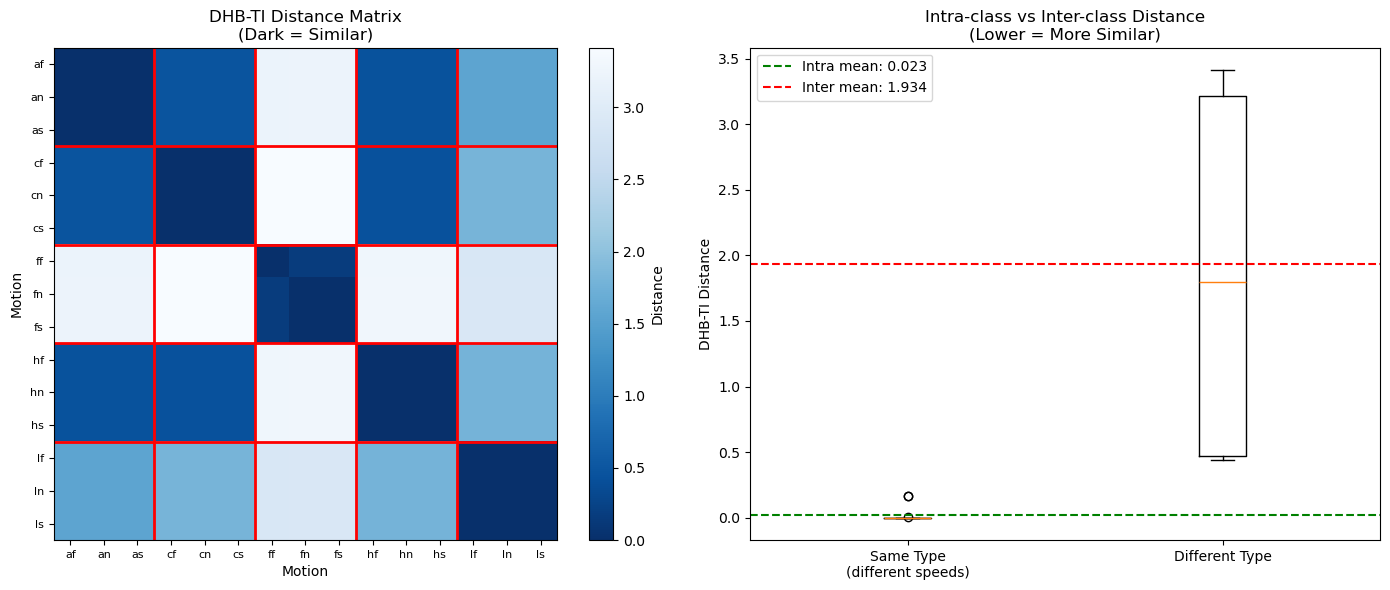

Intra-class distance (same motion, different speed): 0.0231 ± 0.0567
Inter-class distance (different motions):           1.9337 ± 1.1550
Separation ratio: 83.6x


In [44]:
# Visualize distance matrix: Invariants cluster by motion TYPE, not speed

# Compute pairwise distance matrix
keys = list(motion_db.keys())
n = len(keys)
dist_matrix = np.zeros((n, n))

for i, k1 in enumerate(keys):
    for j, k2 in enumerate(keys):
        dist_matrix[i, j] = invariant_distance(
            motion_db[k1]['invariants'], 
            motion_db[k2]['invariants']
        )

# Reorder by motion type for visualization
type_order = sorted(range(n), key=lambda i: (motion_db[keys[i]]['type'], motion_db[keys[i]]['variant']))
keys_sorted = [keys[i] for i in type_order]
dist_sorted = dist_matrix[np.ix_(type_order, type_order)]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Heatmap
ax1 = axes[0]
im = ax1.imshow(dist_sorted, cmap='Blues_r', aspect='auto')
ax1.set_xticks(range(n))
ax1.set_yticks(range(n))
ax1.set_xticklabels([k.split('_')[0][0] + k.split('_')[1][0] for k in keys_sorted], fontsize=8)
ax1.set_yticklabels([k.split('_')[0][0] + k.split('_')[1][0] for k in keys_sorted], fontsize=8)
ax1.set_title('DHB-TI Distance Matrix\n(Dark = Similar)')
ax1.set_xlabel('Motion')
ax1.set_ylabel('Motion')

# Add block boundaries for motion types
boundaries = [0]
current_type = motion_db[keys_sorted[0]]['type']
for i, k in enumerate(keys_sorted):
    if motion_db[k]['type'] != current_type:
        boundaries.append(i)
        current_type = motion_db[k]['type']
boundaries.append(n)

for b in boundaries[1:-1]:
    ax1.axhline(b - 0.5, color='red', linewidth=2)
    ax1.axvline(b - 0.5, color='red', linewidth=2)

plt.colorbar(im, ax=ax1, label='Distance')

# Bar chart: Intra-class vs Inter-class distance
ax2 = axes[1]
intra_dists = []
inter_dists = []

for i, k1 in enumerate(keys):
    for j, k2 in enumerate(keys):
        if i < j:
            if motion_db[k1]['type'] == motion_db[k2]['type']:
                intra_dists.append(dist_matrix[i, j])
            else:
                inter_dists.append(dist_matrix[i, j])

ax2.boxplot([intra_dists, inter_dists], labels=['Same Type\n(different speeds)', 'Different Type'])
ax2.set_ylabel('DHB-TI Distance')
ax2.set_title('Intra-class vs Inter-class Distance\n(Lower = More Similar)')
ax2.axhline(np.mean(intra_dists), color='green', linestyle='--', label=f'Intra mean: {np.mean(intra_dists):.3f}')
ax2.axhline(np.mean(inter_dists), color='red', linestyle='--', label=f'Inter mean: {np.mean(inter_dists):.3f}')
ax2.legend()

plt.tight_layout()
plt.show()

print(f'Intra-class distance (same motion, different speed): {np.mean(intra_dists):.4f} ± {np.std(intra_dists):.4f}')
print(f'Inter-class distance (different motions):           {np.mean(inter_dists):.4f} ± {np.std(inter_dists):.4f}')
print(f'Separation ratio: {np.mean(inter_dists)/np.mean(intra_dists):.1f}x')

### Motion Retrieval Summary

**Key Results:**
1. **Invariant-based retrieval** correctly identifies motion type regardless of:
   - Execution speed (slow, normal, fast)
   - Sampling rate (25, 50, 100 points)
   - Starting position (random offsets)

2. **Position-based retrieval** fails because raw trajectories are sensitive to these variations

3. **Distance matrix** shows clear block-diagonal structure:
   - Motions of the same type cluster together
   - Different speed variants of the same motion have small distances

**Applications:**
- Motion primitive libraries for robot skills
- Demonstration retrieval for imitation learning
- Cross-embodiment motion transfer
- Action recognition from partial observations

=== Progress Variable Comparison ===
Translation progress (arc-length): total = 1.651
Angular progress:                  total = 1.243
Hybrid progress (α=0.5):           total = 1.447


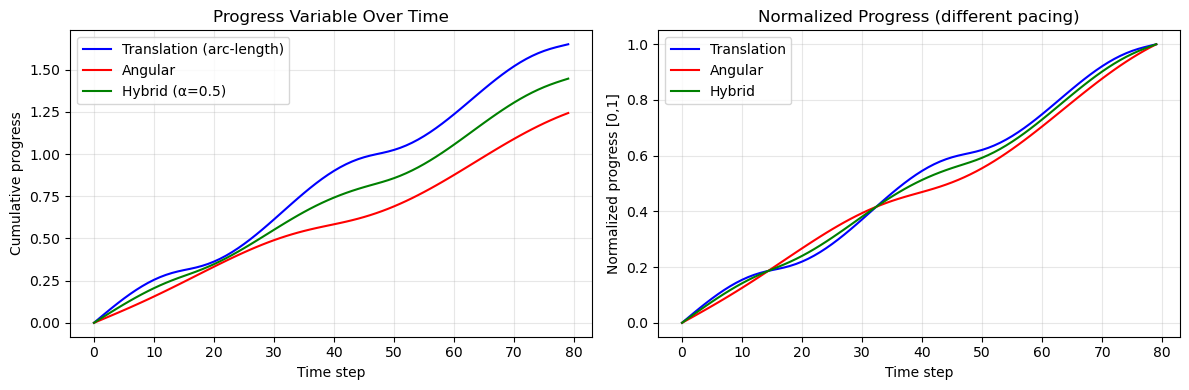


Interpretation:
  - Translation: faster progress when moving quickly in space
  - Angular: faster progress when rotating quickly
  - Hybrid: balanced — good default for SE(3) motions


In [45]:
# Compare different progress types
print("=== Progress Variable Comparison ===")

# Use the original trajectory from earlier
prog_trans = compute_progress(positions, quaternions, kind="translation")
prog_angular = compute_progress(positions, quaternions, kind="angular")
prog_hybrid = compute_progress(positions, quaternions, kind="hybrid", alpha=0.5)

print(f"Translation progress (arc-length): total = {prog_trans[-1]:.3f}")
print(f"Angular progress:                  total = {prog_angular[-1]:.3f}")
print(f"Hybrid progress (α=0.5):           total = {prog_hybrid[-1]:.3f}")

# Plot progress curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(prog_trans, 'b-', label='Translation (arc-length)')
ax.plot(prog_angular, 'r-', label='Angular')
ax.plot(prog_hybrid, 'g-', label='Hybrid (α=0.5)')
ax.set_xlabel('Time step')
ax.set_ylabel('Cumulative progress')
ax.set_title('Progress Variable Over Time')
ax.legend()
ax.grid(True, alpha=0.3)

# Normalized to [0,1]
ax = axes[1]
ax.plot(prog_trans / prog_trans[-1], 'b-', label='Translation')
ax.plot(prog_angular / prog_angular[-1], 'r-', label='Angular')
ax.plot(prog_hybrid / prog_hybrid[-1], 'g-', label='Hybrid')
ax.set_xlabel('Time step')
ax.set_ylabel('Normalized progress [0,1]')
ax.set_title('Normalized Progress (different pacing)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nInterpretation:")
print("  - Translation: faster progress when moving quickly in space")
print("  - Angular: faster progress when rotating quickly")
print("  - Hybrid: balanced — good default for SE(3) motions")

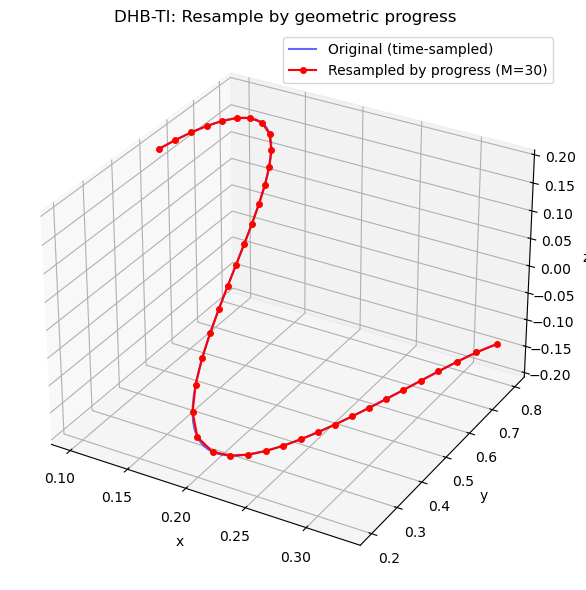

In [43]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot(positions[:, 0], positions[:, 1], positions[:, 2], 'b-', alpha=0.6, label='Original (time-sampled)')
ax.plot(pos_ti[:, 0], pos_ti[:, 1], pos_ti[:, 2], 'ro-', markersize=4, label=f'Resampled by progress (M={M})')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title('DHB-TI: Resample by geometric progress')
ax.legend()
plt.tight_layout()
plt.show()

---
## 6. Trajectory adaptation (retargeting)

We can **adapt** a demo trajectory to a **new initial pose** (and optionally goal): resample the demo, encode to invariants, then **decode** from the new initial pose. The motion *style* (invariants) is preserved while the start (and optionally end) pose is changed — useful for transferring a motion to a different robot or workspace.

**How it works:**
- The demo trajectory is resampled and encoded to DHB invariants
- A **CasADi NLP** solves for new invariants that satisfy boundary constraints while minimizing deviation from the demo
- If CasADi is unavailable or the NLP fails, a smooth interpolation fallback is used

`generate_trajectory(demo_pos, demo_quat, pose_init, pose_goal, traj_length, ...)` returns the adapted positions and quaternions.

The solver reports which method was used: `"casadi"` for the NLP solver, `"interpolation"` for the fallback.

In [11]:
# Check if CasADi solver is available
print(f"CasADi available: {HAS_CASADI}")

# Example 1: Simple position offset (same orientation)
pose_init = {"position": positions[0].copy(), "quaternion": quaternions[0].copy()}
pose_goal = {
    "position": positions[-1].copy() + np.array([0.15, 0.1, 0.05]),
    "quaternion": quaternions[-1].copy(),
}
traj_length = 80

result = generate_trajectory(
    positions, quaternions,
    pose_init, pose_goal,
    traj_length=traj_length,
    smoothing=False,
    dhb_method=DHBMethod.DOUBLE_REFLECTION,
    use_casadi=True,  # Try CasADi solver first
    verbose=False,
)
adapted_pos = result["adapted_pos_data"]
adapted_quat = result["adapted_quat_data"]

print(f"Solver used: {result['solver']}")
print(f"Adapted trajectory length: {len(adapted_pos)}")
print(f"Start matches init: {np.allclose(adapted_pos[0], pose_init['position'], atol=1e-3)}")
print(f"End matches goal: {np.allclose(adapted_pos[-1], pose_goal['position'], atol=1e-3)}")

CasADi available: True

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

Solver used: casadi
Adapted trajectory length: 80
Start matches init: True
End matches goal: True


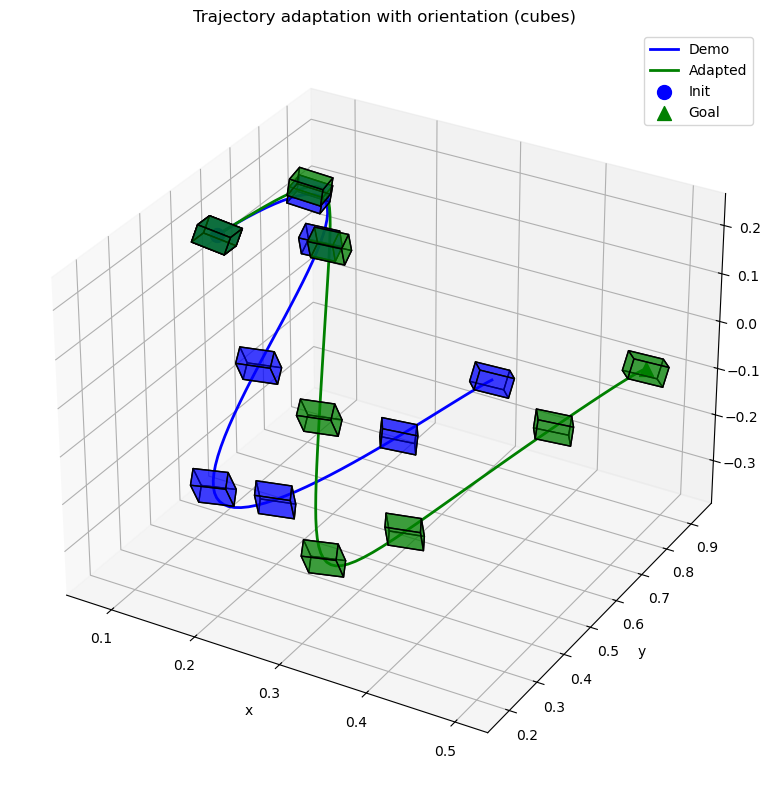

Solver used: casadi
Start position matches: True
End position matches: True


In [12]:
# Plot with orientation cubes to visualize rotation adaptation
from dhb_xr.visualization.plot import plot_se3_trajectories, draw_box, draw_frame

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot demo trajectory with blue cubes
plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     "Adapted": {"positions": adapted_pos, "quaternions": adapted_quat}},
    ax=ax,
    show_orientation=True,
    vis_type="cube",
    box_size_scale=0.04,
    num_frames=8,
    title="Trajectory adaptation with orientation (cubes)",
    show_legend=True,
)

# Mark init and goal
ax.scatter(*pose_init["position"], color='blue', s=100, marker='o', label='Init', zorder=10)
ax.scatter(*pose_goal["position"], color='green', s=100, marker='^', label='Goal', zorder=10)

ax.legend()
plt.tight_layout()
plt.show()

print(f"Solver used: {result['solver']}")
print(f"Start position matches: {np.allclose(adapted_pos[0], pose_init['position'], atol=1e-3)}")
print(f"End position matches: {np.allclose(adapted_pos[-1], pose_goal['position'], atol=1e-3)}")

### 6.1 Diverse trajectory adaptation examples

Let's demonstrate the **generality** of trajectory adaptation with different scenarios:
1. **Large position offset** — move the entire motion to a different location
2. **Different start and goal** — stretch or compress the motion
3. **Rotation change** — apply a different initial orientation

The invariants capture the *shape* of the motion, so the adapted trajectory preserves the motion style.

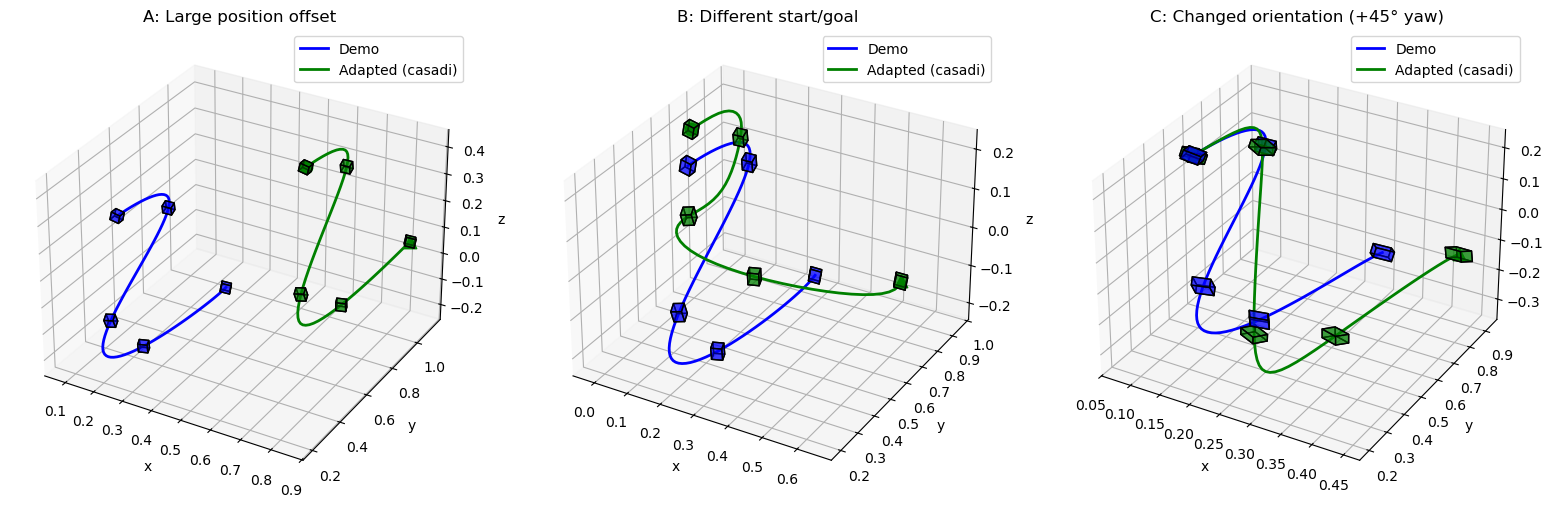

Example A solver: casadi
Example B solver: casadi
Example C solver: casadi


In [13]:
# Create multiple adapted trajectories with different boundary conditions
# Using cube visualization to show orientation changes

fig = plt.figure(figsize=(16, 5))

# --- Example A: Large position offset (pure translation) ---
ax1 = fig.add_subplot(131, projection='3d')
offset_A = np.array([0.5, 0.3, 0.2])  # Large offset
pose_init_A = {"position": positions[0].copy() + offset_A, "quaternion": quaternions[0].copy()}
pose_goal_A = {"position": positions[-1].copy() + offset_A, "quaternion": quaternions[-1].copy()}
result_A = generate_trajectory(positions, quaternions, pose_init_A, pose_goal_A, traj_length=60, use_casadi=True)

# Plot with cubes
plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Adapted ({result_A['solver']})": {"positions": result_A["adapted_pos_data"], "quaternions": result_A["adapted_quat_data"]}},
    ax=ax1, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="A: Large position offset"
)
ax1.scatter(*pose_init_A["position"], color='green', s=80, marker='o', zorder=10)
ax1.scatter(*pose_goal_A["position"], color='green', s=80, marker='^', zorder=10)

# --- Example B: Different start and goal (stretch/warp) ---
ax2 = fig.add_subplot(132, projection='3d')
pose_init_B = {"position": positions[0].copy() + np.array([-0.1, 0.2, 0.0]), "quaternion": quaternions[0].copy()}
pose_goal_B = {"position": positions[-1].copy() + np.array([0.3, -0.1, 0.1]), "quaternion": quaternions[-1].copy()}
result_B = generate_trajectory(positions, quaternions, pose_init_B, pose_goal_B, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Adapted ({result_B['solver']})": {"positions": result_B["adapted_pos_data"], "quaternions": result_B["adapted_quat_data"]}},
    ax=ax2, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="B: Different start/goal"
)
ax2.scatter(*pose_init_B["position"], color='green', s=80, marker='o', zorder=10)
ax2.scatter(*pose_goal_B["position"], color='green', s=80, marker='^', zorder=10)

# --- Example C: Changed initial orientation (rotation change) ---
ax3 = fig.add_subplot(133, projection='3d')
angle_z = np.pi / 4  # 45 degrees around z-axis
quat_rot = np.array([np.cos(angle_z/2), 0, 0, np.sin(angle_z/2)])  # wxyz
pose_init_C = {"position": positions[0].copy(), "quaternion": geom.quat_multiply(quat_rot, quaternions[0])}
pose_goal_C = {"position": positions[-1].copy() + np.array([0.1, 0.1, 0.0]), "quaternion": geom.quat_multiply(quat_rot, quaternions[-1])}
result_C = generate_trajectory(positions, quaternions, pose_init_C, pose_goal_C, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Adapted ({result_C['solver']})": {"positions": result_C["adapted_pos_data"], "quaternions": result_C["adapted_quat_data"]}},
    ax=ax3, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="C: Changed orientation (+45° yaw)"
)
ax3.scatter(*pose_init_C["position"], color='green', s=80, marker='o', zorder=10)
ax3.scatter(*pose_goal_C["position"], color='green', s=80, marker='^', zorder=10)

plt.tight_layout()
plt.show()

print(f"Example A solver: {result_A['solver']}")
print(f"Example B solver: {result_B['solver']}")
print(f"Example C solver: {result_C['solver']}")

In [16]:
# Quantitative analysis: verify boundary constraints are satisfied
print("=== Boundary constraint verification ===")
for name, result, pose_init, pose_goal in [
    ("A", result_A, pose_init_A, pose_goal_A),
    ("B", result_B, pose_init_B, pose_goal_B),
    ("C", result_C, pose_init_C, pose_goal_C),
]:
    pos_start_err = np.linalg.norm(result["adapted_pos_data"][0] - pose_init["position"])
    pos_end_err = np.linalg.norm(result["adapted_pos_data"][-1] - pose_goal["position"])
    print(f"Example {name}: start error = {pos_start_err:.6f}, end error = {pos_end_err:.6f}")

=== Boundary constraint verification ===
Example A: start error = 0.000000, end error = 0.000000
Example B: start error = 0.000000, end error = 0.000000
Example C: start error = 0.000000, end error = 0.000000


### 6.2 Extreme adaptation scenarios

Let's push the limits with more extreme scenarios to demonstrate the **robustness** of the CasADi NLP solver:
1. **Mirror/flip** — the goal is before the start (reversed direction)
2. **Scale change** — double the spatial extent
3. **Multi-axis offset** — large offset in all directions with rotation

In [ ]:
# Extreme adaptation scenarios with cube visualization
fig = plt.figure(figsize=(16, 5))

# --- Example D: Reversed direction (goal before start) ---
ax1 = fig.add_subplot(131, projection='3d')
pose_init_D = {"position": positions[-1].copy(), "quaternion": quaternions[-1].copy()}  # Swap!
pose_goal_D = {"position": positions[0].copy(), "quaternion": quaternions[0].copy()}
result_D = generate_trajectory(positions, quaternions, pose_init_D, pose_goal_D, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Reversed ({result_D['solver']})": {"positions": result_D["adapted_pos_data"], "quaternions": result_D["adapted_quat_data"]}},
    ax=ax1, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="D: Reversed direction"
)
ax1.scatter(*pose_init_D["position"], color='cyan', s=80, marker='o', label='Start (was end)', zorder=10)
ax1.scatter(*pose_goal_D["position"], color='cyan', s=80, marker='^', label='Goal (was start)', zorder=10)

# --- Example E: Scale change (double spatial extent) ---
ax2 = fig.add_subplot(132, projection='3d')
scale = 2.0
center = positions.mean(axis=0)
pos_scaled_start = center + scale * (positions[0] - center)
pos_scaled_end = center + scale * (positions[-1] - center)
pose_init_E = {"position": pos_scaled_start, "quaternion": quaternions[0].copy()}
pose_goal_E = {"position": pos_scaled_end, "quaternion": quaternions[-1].copy()}
result_E = generate_trajectory(positions, quaternions, pose_init_E, pose_goal_E, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Scaled 2x ({result_E['solver']})": {"positions": result_E["adapted_pos_data"], "quaternions": result_E["adapted_quat_data"]}},
    ax=ax2, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="E: Scaled 2x from center"
)
ax2.scatter(*pose_init_E["position"], color='orange', s=80, marker='o', zorder=10)
ax2.scatter(*pose_goal_E["position"], color='orange', s=80, marker='^', zorder=10)

# --- Example F: Large multi-axis offset with rotation ---
ax3 = fig.add_subplot(133, projection='3d')
offset_F = np.array([1.0, -0.5, 0.3])
angle_y = np.pi / 6  # 30 degrees around y
quat_rot_F = np.array([np.cos(angle_y/2), 0, np.sin(angle_y/2), 0])  # wxyz
pose_init_F = {"position": positions[0].copy() + offset_F, "quaternion": geom.quat_multiply(quat_rot_F, quaternions[0])}
pose_goal_F = {"position": positions[-1].copy() + offset_F + np.array([0.2, 0.2, 0.1]), "quaternion": geom.quat_multiply(quat_rot_F, quaternions[-1])}
result_F = generate_trajectory(positions, quaternions, pose_init_F, pose_goal_F, traj_length=60, use_casadi=True)

plot_se3_trajectories(
    {"Demo": {"positions": positions, "quaternions": quaternions},
     f"Offset+rot ({result_F['solver']})": {"positions": result_F["adapted_pos_data"], "quaternions": result_F["adapted_quat_data"]}},
    ax=ax3, show_orientation=True, vis_type="cube", box_size_scale=0.03, num_frames=5, show_legend=True, title="F: Large offset + 30° pitch"
)
ax3.scatter(*pose_init_F["position"], color='brown', s=80, marker='o', zorder=10)
ax3.scatter(*pose_goal_F["position"], color='brown', s=80, marker='^', zorder=10)

plt.tight_layout()
plt.show()

print(f"\n=== Extreme scenarios results ===")
for name, result, pi, pg in [("D", result_D, pose_init_D, pose_goal_D), ("E", result_E, pose_init_E, pose_goal_E), ("F", result_F, pose_init_F, pose_goal_F)]:
    se = np.linalg.norm(result["adapted_pos_data"][0] - pi["position"])
    ee = np.linalg.norm(result["adapted_pos_data"][-1] - pg["position"])
    print(f"Example {name}: solver={result['solver']}, start_err={se:.6f}, end_err={ee:.6f}")

---
## 7. VLA Tokenization (DHB-Token)

For **Vision-Language-Action** (VLA) models, continuous DHB invariants can be discretized into tokens using VQ-VAE or RVQ.

### DHB-Token Pipeline

```
SE(3) trajectory → DHB invariants → VQ-VAE → Discrete tokens → [Compression] → Storage/VLA
```

**Benefits:**
- Causal (streaming-compatible) encoding
- Compact representation for VLA training
- Frame-independent (works across embodiments)
- **Compressible**: Further 5-15x reduction via BPE, entropy coding (Section 7b)

**References:**
- [VQ-VLA (ICCV 2025)](https://openaccess.thecvf.com/content/ICCV2025/papers/Wang_VQ-VLA_Improving_Vision-Language-Action_Models_via_Scaling_Vector-Quantized_Action_Tokenizers_ICCV_2025_paper.pdf)
- [FAST (2025)](https://arxiv.org/abs/2501.09747): Efficient action tokenization with DCT + BPE

In [10]:
try:
    import torch
    from dhb_xr.tokenization.vqvae import DHBTokenizer
    
    print("=== VLA Tokenization Demo ===\n")
    
    # Prepare invariants
    inv_combined = np.concatenate([linear_inv, angular_inv], axis=1).astype(np.float32)
    x = torch.from_numpy(inv_combined).unsqueeze(0)  # (1, T, 8)
    T_seq = x.shape[1]
    
    # Create tokenizer
    codebook_size = 64
    latent_dim = 16
    model = DHBTokenizer(invariant_dim=8, latent_dim=latent_dim, codebook_size=codebook_size)
    
    # Forward pass
    indices, reconstructed, z, z_q = model(x)
    
    print(f"Input invariants: {x.shape} (batch, time, features)")
    print(f"Latent z: {z.shape}")
    print(f"Token indices: {indices.shape}, unique tokens: {len(torch.unique(indices))}/{codebook_size}")
    print(f"Reconstructed: {reconstructed.shape}")
    
    # Compute reconstruction error
    rec_mse = torch.nn.functional.mse_loss(reconstructed, x).item()
    print(f"\nReconstruction MSE: {rec_mse:.6f}")
    
    # Per-step error
    per_step_mse = ((reconstructed - x) ** 2).mean(dim=2).squeeze().detach().numpy()
    
    HAS_TORCH = True
except ImportError as e:
    print(f"Skipping VLA tokenization (torch required): {e}")
    HAS_TORCH = False

=== VLA Tokenization Demo ===

Input invariants: torch.Size([1, 82, 8]) (batch, time, features)
Latent z: torch.Size([1, 82, 16])
Token indices: torch.Size([1, 82]), unique tokens: 4/64
Reconstructed: torch.Size([1, 82, 8])

Reconstruction MSE: 0.042176


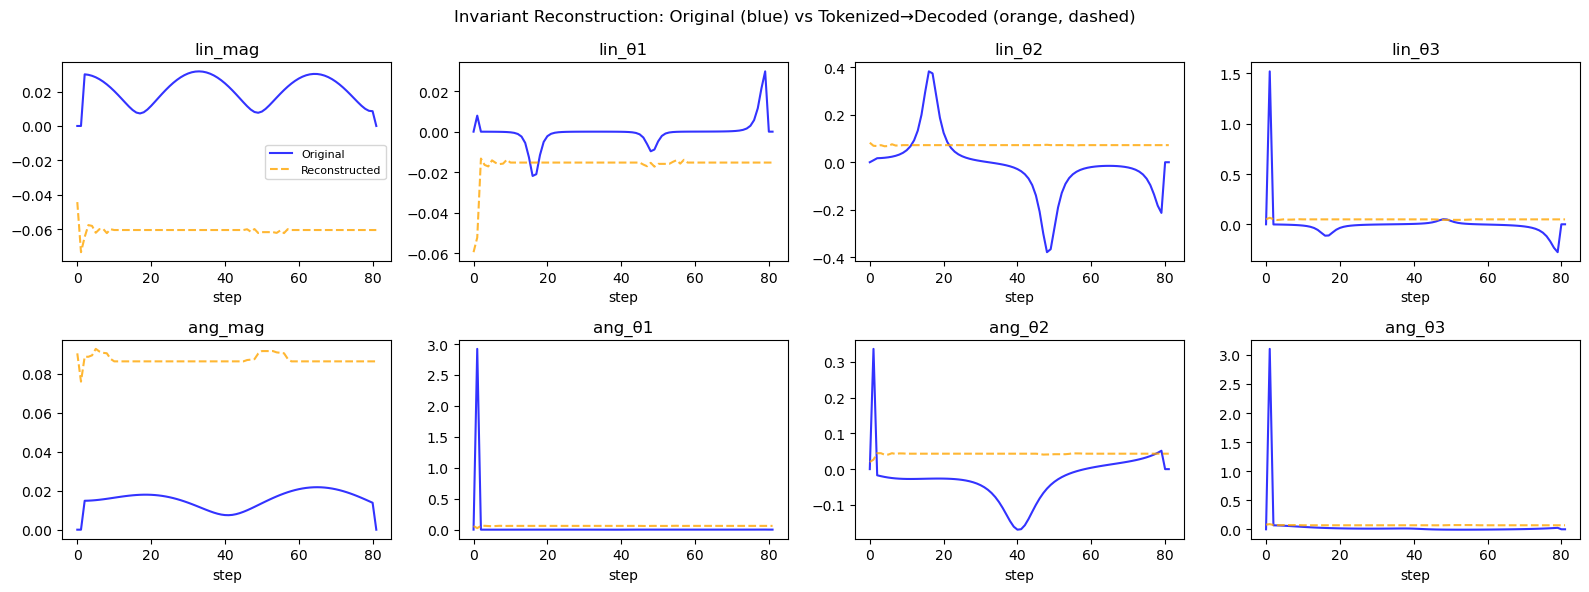

In [24]:
if HAS_TORCH:
    # Plot 1: Original vs Reconstructed Invariants
    fig, axes = plt.subplots(2, 4, figsize=(16, 6))
    fig.suptitle('Invariant Reconstruction: Original (blue) vs Tokenized→Decoded (orange, dashed)', fontsize=12)
    
    inv_names = ['lin_mag', 'lin_θ1', 'lin_θ2', 'lin_θ3', 'ang_mag', 'ang_θ1', 'ang_θ2', 'ang_θ3']
    x_np = x.squeeze().detach().numpy()
    rec_np = reconstructed.squeeze().detach().numpy()
    
    for j in range(8):
        row, col = j // 4, j % 4
        axes[row, col].plot(x_np[:, j], 'b-', alpha=0.8, label='Original')
        axes[row, col].plot(rec_np[:, j], 'orange', linestyle='--', alpha=0.8, label='Reconstructed')
        axes[row, col].set_title(inv_names[j])
        axes[row, col].set_xlabel('step')
        if j == 0:
            axes[row, col].legend(fontsize=8)
    
    plt.tight_layout()
    plt.show()

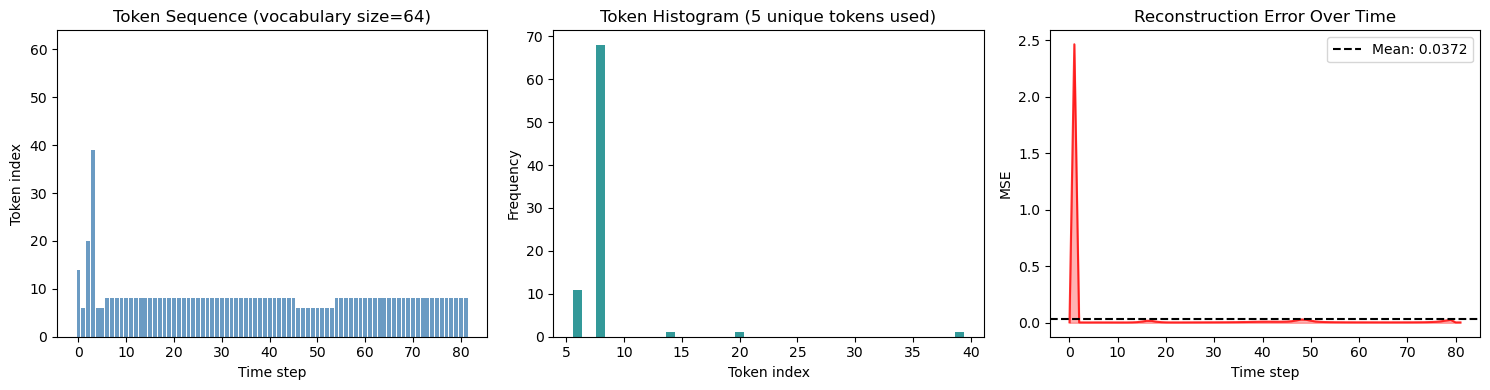

In [25]:
if HAS_TORCH:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Plot 2a: Token sequence visualization
    token_seq = indices.squeeze().detach().numpy()
    axes[0].bar(range(len(token_seq)), token_seq, color='steelblue', alpha=0.8)
    axes[0].set_xlabel('Time step')
    axes[0].set_ylabel('Token index')
    axes[0].set_title(f'Token Sequence (vocabulary size={codebook_size})')
    axes[0].set_ylim(0, codebook_size)
    
    # Plot 2b: Token frequency histogram
    unique, counts = np.unique(token_seq, return_counts=True)
    axes[1].bar(unique, counts, color='teal', alpha=0.8)
    axes[1].set_xlabel('Token index')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title(f'Token Histogram ({len(unique)} unique tokens used)')
    
    # Plot 2c: Per-step reconstruction error
    axes[2].plot(per_step_mse, 'r-', alpha=0.8)
    axes[2].fill_between(range(len(per_step_mse)), per_step_mse, alpha=0.3, color='red')
    axes[2].set_xlabel('Time step')
    axes[2].set_ylabel('MSE')
    axes[2].set_title('Reconstruction Error Over Time')
    axes[2].axhline(y=per_step_mse.mean(), color='k', linestyle='--', label=f'Mean: {per_step_mse.mean():.4f}')
    axes[2].legend()
    
    plt.tight_layout()
    plt.show()

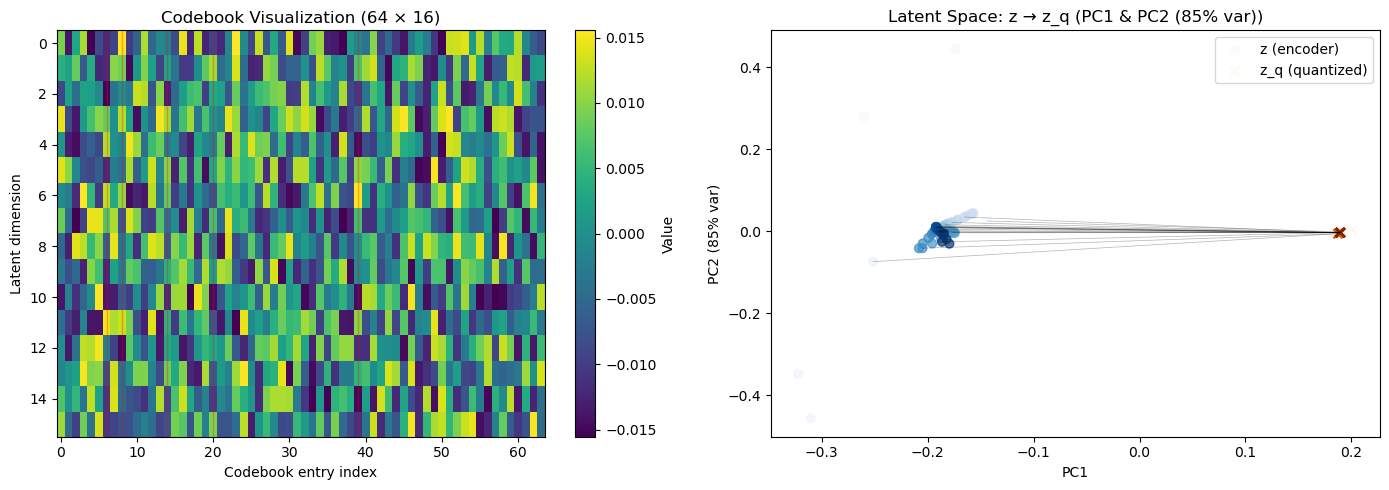

In [26]:
if HAS_TORCH:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot 3a: Codebook heatmap
    codebook = model.vq.embedding.weight.detach().numpy()  # (codebook_size, latent_dim)
    im = axes[0].imshow(codebook.T, aspect='auto', cmap='viridis')
    axes[0].set_xlabel('Codebook entry index')
    axes[0].set_ylabel('Latent dimension')
    axes[0].set_title(f'Codebook Visualization ({codebook_size} × {latent_dim})')
    plt.colorbar(im, ax=axes[0], label='Value')
    
    # Highlight used tokens
    used_tokens = np.unique(token_seq)
    for tok in used_tokens:
        axes[0].axvline(x=tok, color='red', alpha=0.3, linewidth=1)
    axes[0].set_xlim(-0.5, codebook_size - 0.5)
    
    # Plot 3b: Latent space visualization (2 principal dimensions)
    z_np = z.squeeze().detach().numpy()  # (T, latent_dim)
    z_q_np = z_q.squeeze().detach().numpy()
    
    # Simple 2D projection using first 2 dimensions (no sklearn dependency)
    # Or use SVD-based PCA if numpy
    try:
        # Center the data
        combined = np.vstack([z_np, z_q_np])
        mean = combined.mean(axis=0)
        centered = combined - mean
        # SVD for PCA
        U, S, Vt = np.linalg.svd(centered, full_matrices=False)
        combined_2d = centered @ Vt[:2].T
        z_2d = combined_2d[:len(z_np)]
        z_q_2d = combined_2d[len(z_np):]
        explained_var = (S[:2]**2).sum() / (S**2).sum()
        pca_label = f'PC1 & PC2 ({explained_var:.0%} var)'
    except Exception:
        # Fallback: just use first 2 dimensions
        z_2d = z_np[:, :2]
        z_q_2d = z_q_np[:, :2]
        pca_label = 'Dim 0 & 1'
    
    # Color by time
    colors = np.arange(len(z_2d))
    axes[1].scatter(z_2d[:, 0], z_2d[:, 1], c=colors, cmap='Blues', alpha=0.7, s=40, label='z (encoder)')
    axes[1].scatter(z_q_2d[:, 0], z_q_2d[:, 1], c=colors, cmap='Oranges', alpha=0.7, s=40, marker='x', label='z_q (quantized)')
    # Draw lines connecting z to z_q
    for j in range(0, len(z_2d), 5):  # Every 5th point
        axes[1].plot([z_2d[j, 0], z_q_2d[j, 0]], [z_2d[j, 1], z_q_2d[j, 1]], 'k-', alpha=0.3, linewidth=0.5)
    axes[1].set_xlabel(pca_label.split('&')[0].strip())
    axes[1].set_ylabel(pca_label.split('&')[1].strip() if '&' in pca_label else 'Dim 1')
    axes[1].set_title(f'Latent Space: z → z_q ({pca_label})')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

### Key observations

1. **Reconstruction quality**: The VQ-VAE captures the main structure of invariants, with higher error at rapid transitions
2. **Codebook utilization**: Not all tokens are used equally — some are more common (representing typical motion patterns)
3. **Latent quantization**: PCA shows how encoder outputs (z) are mapped to nearest codebook vectors (z_q)

### ⚠️ Why is reconstruction error so high?

**The model is untrained!** The `DHBTokenizer` shown here uses **random weights**. In practice:

| Condition | Expected Position Error |
|-----------|------------------------|
| **Untrained (random)** | 1.0 – 5.0+ (meaningless reconstruction) |
| **Trained (small dataset)** | 0.05 – 0.2 |
| **Trained (large dataset)** | < 0.01 |

To train the VQ-VAE:
```python
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
for batch in dataloader:
    indices, reconstructed, z, z_q = model(batch)
    loss = model.loss(batch, reconstructed, z, z_q, beta=0.25)
    loss.backward()
    optimizer.step()
```

### Causal streaming for VLA

The encoder uses **causal convolutions** (no future information), so tokens can be generated **step-by-step** as new observations arrive:

```python
# Streaming tokenization (pseudo-code)
for t in range(T):
    invariant_t = encode_dhb_dr_step(pose_t, pose_{t-1}, ...)  # Get new invariant
    token_t = tokenizer.encode_step(invariant_t)              # Tokenize causally
    next_token = vla_model.predict(vision, language, tokens[:t+1])  # Predict next
```

This enables **real-time action generation** in VLA systems.

=== Token → Trajectory Reconstruction ===
⚠️  NOTE: Model is UNTRAINED (random weights) — high reconstruction error is expected!
    A trained VQ-VAE on motion data would achieve much lower error.



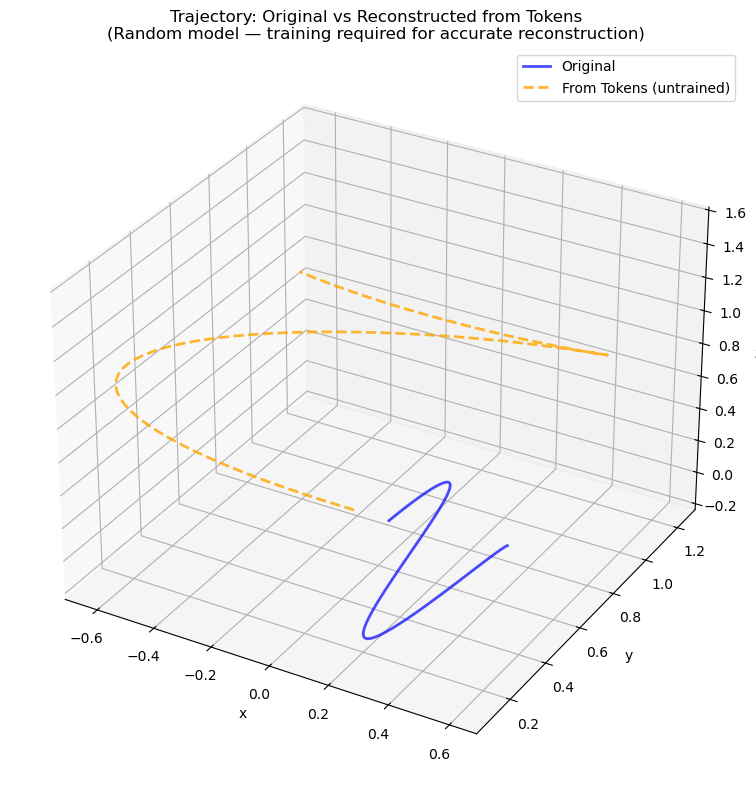

Position error — mean: 1.2363, max: 1.6443
  → With training, expect mean error < 0.01 for smooth trajectories

Tokenization compression: 82 steps × 8 floats → 82 tokens (2.56 KB → 82 bytes)


In [27]:
if HAS_TORCH:
    # Decode tokens back to trajectory
    print("=== Token → Trajectory Reconstruction ===")
    print("⚠️  NOTE: Model is UNTRAINED (random weights) — high reconstruction error is expected!")
    print("    A trained VQ-VAE on motion data would achieve much lower error.\n")
    
    # Get reconstructed invariants
    lin_inv_rec = rec_np[:, :4]
    ang_inv_rec = rec_np[:, 4:]
    
    # Decode to trajectory
    init_pose = {"position": positions[0].copy(), "quaternion": quaternions[0].copy()}
    traj_rec = decode_dhb_dr(lin_inv_rec, ang_inv_rec, init_pose, method="pos", drop_padded=True)
    pos_rec = traj_rec["positions"]
    quat_rec = traj_rec["quaternions"]
    
    # Plot original vs token-reconstructed trajectory
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # Trim to same length
    n_plot = min(len(positions), len(pos_rec))
    
    ax.plot(positions[:n_plot, 0], positions[:n_plot, 1], positions[:n_plot, 2], 'b-', linewidth=2, alpha=0.7, label='Original')
    ax.plot(pos_rec[:n_plot, 0], pos_rec[:n_plot, 1], pos_rec[:n_plot, 2], 'orange', linestyle='--', linewidth=2, alpha=0.8, label='From Tokens (untrained)')
    
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_title('Trajectory: Original vs Reconstructed from Tokens\n(Random model — training required for accurate reconstruction)')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    pos_error = np.linalg.norm(positions[:n_plot] - pos_rec[:n_plot], axis=1)
    print(f"Position error — mean: {pos_error.mean():.4f}, max: {pos_error.max():.4f}")
    print(f"  → With training, expect mean error < 0.01 for smooth trajectories")
    print(f"\nTokenization compression: {T_seq} steps × 8 floats → {T_seq} tokens ({T_seq * 8 * 4 / 1024:.2f} KB → {T_seq * 1:.0f} bytes)")

### Training the VQ-VAE

Let's train the tokenizer on this trajectory to see how reconstruction improves. We'll:
1. Generate multiple augmented versions of the trajectory (with noise, scaling)
2. Train for 200 epochs
3. Compare reconstruction before vs after training

In [28]:
if HAS_TORCH:
    import torch.optim as optim
    
    # Create a fresh model for training demo
    model_trained = DHBTokenizer(invariant_dim=8, latent_dim=16, codebook_size=64)
    optimizer = optim.Adam(model_trained.parameters(), lr=3e-3)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=300, eta_min=1e-5)
    
    # Data augmentation: create variations of the trajectory
    def augment_invariants(inv, n_aug=20):
        """Create augmented versions with noise and scaling."""
        augmented = [inv]
        for _ in range(n_aug - 1):
            noise = np.random.randn(*inv.shape) * 0.02  # Small noise
            scale = np.random.uniform(0.9, 1.1)
            augmented.append(inv * scale + noise)
        return np.stack(augmented, axis=0).astype(np.float32)
    
    # Create training batch
    train_data = augment_invariants(inv_combined, n_aug=32)
    train_tensor = torch.from_numpy(train_data)  # (32, T, 8)
    
    print(f"Training data shape: {train_tensor.shape}")
    print(f"Training for 300 epochs with cosine LR schedule...")
    
    # Training loop
    losses = []
    best_loss = float('inf')
    best_state = None
    for epoch in range(300):
        optimizer.zero_grad()
        indices, reconstructed, z, z_q = model_trained(train_tensor)
        loss = model_trained.loss(train_tensor, reconstructed, z, z_q, beta=0.25)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_trained.parameters(), 1.0)  # Gradient clipping
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
        
        # Save best model
        if loss.item() < best_loss:
            best_loss = loss.item()
            best_state = {k: v.clone() for k, v in model_trained.state_dict().items()}
        
        if (epoch + 1) % 100 == 0:
            print(f"  Epoch {epoch+1}: loss = {loss.item():.4f}, lr = {scheduler.get_last_lr()[0]:.2e}")
    
    # Load best model
    model_trained.load_state_dict(best_state)
    print(f"\nTraining complete! Best loss: {best_loss:.4f}")

Training data shape: torch.Size([32, 82, 8])
Training for 300 epochs with cosine LR schedule...
  Epoch 100: loss = 0.0632, lr = 2.25e-03
  Epoch 200: loss = 0.0067, lr = 7.57e-04
  Epoch 300: loss = 0.0052, lr = 1.00e-05

Training complete! Best loss: 0.0052


=== Invariant Reconstruction MSE ===
  Untrained: 0.0372
  Trained:   0.0011
  Improvement: 33.5x better


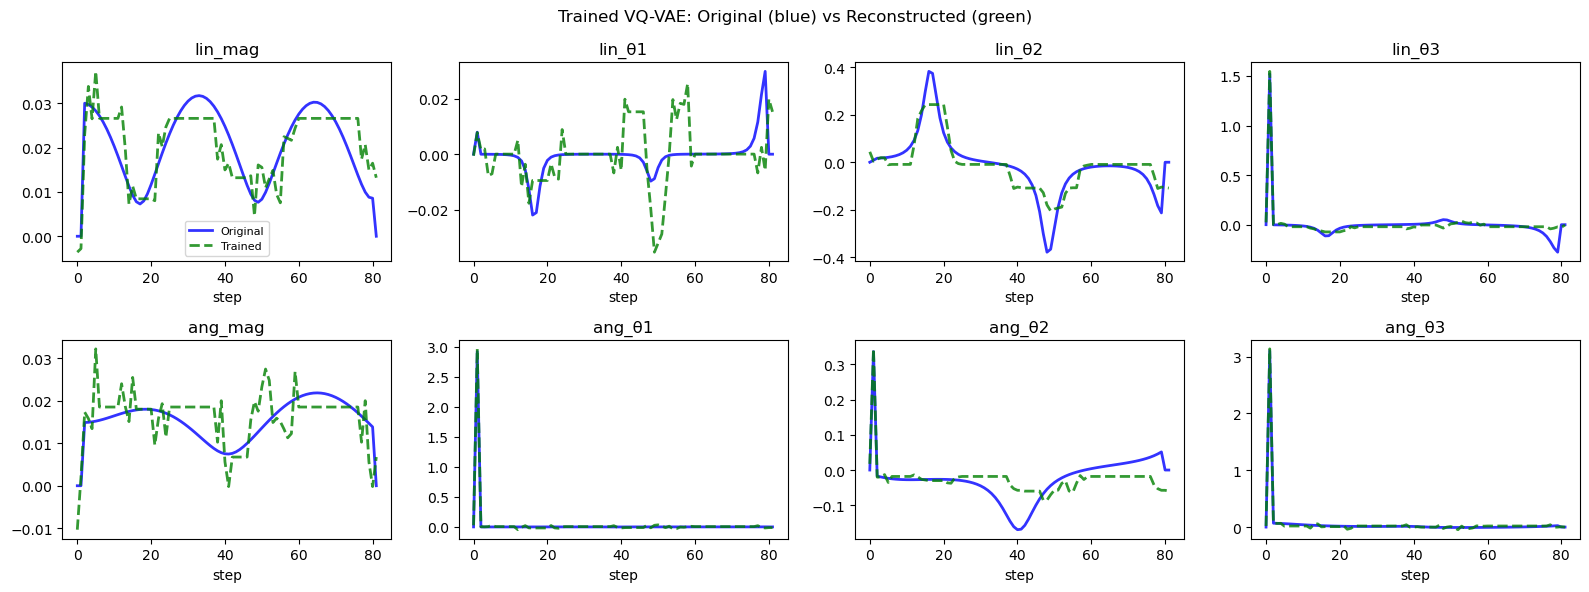

In [29]:
if HAS_TORCH:
    # Compare trained vs untrained on original trajectory
    x_single = torch.from_numpy(inv_combined.astype(np.float32)).unsqueeze(0)
    
    # Untrained model (from before)
    with torch.no_grad():
        _, rec_untrained, _, _ = model(x_single)
        _, rec_trained, _, _ = model_trained(x_single)
    
    mse_untrained = torch.nn.functional.mse_loss(rec_untrained, x_single).item()
    mse_trained = torch.nn.functional.mse_loss(rec_trained, x_single).item()
    
    print("=== Invariant Reconstruction MSE ===")
    print(f"  Untrained: {mse_untrained:.4f}")
    print(f"  Trained:   {mse_trained:.4f}")
    print(f"  Improvement: {mse_untrained/mse_trained:.1f}x better")
    
    # Plot comparison
    fig, axes = plt.subplots(2, 4, figsize=(16, 6))
    fig.suptitle('Trained VQ-VAE: Original (blue) vs Reconstructed (green)', fontsize=12)
    
    inv_names = ['lin_mag', 'lin_θ1', 'lin_θ2', 'lin_θ3', 'ang_mag', 'ang_θ1', 'ang_θ2', 'ang_θ3']
    x_np = x_single.squeeze().numpy()
    rec_trained_np = rec_trained.squeeze().detach().numpy()
    
    for j in range(8):
        row, col = j // 4, j % 4
        axes[row, col].plot(x_np[:, j], 'b-', alpha=0.8, linewidth=2, label='Original')
        axes[row, col].plot(rec_trained_np[:, j], 'g--', alpha=0.8, linewidth=2, label='Trained')
        axes[row, col].set_title(inv_names[j])
        axes[row, col].set_xlabel('step')
        if j == 0:
            axes[row, col].legend(fontsize=8)
    
    plt.tight_layout()
    plt.show()

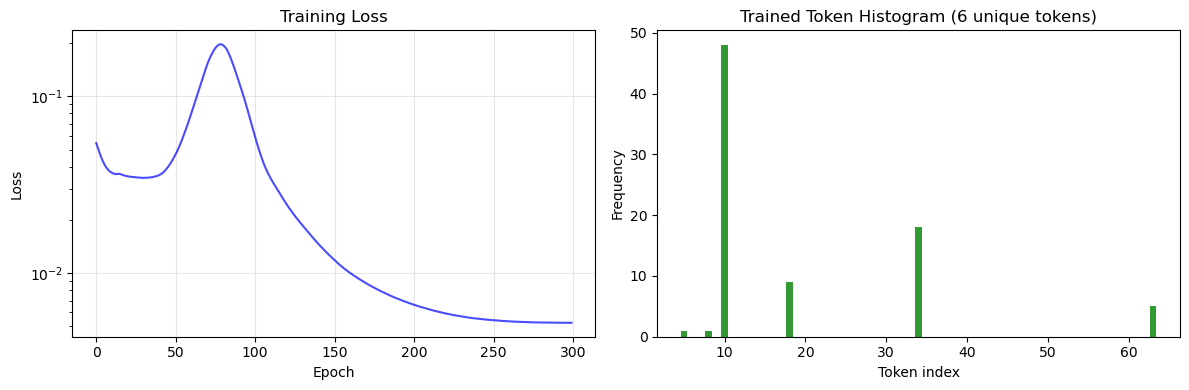

In [30]:
if HAS_TORCH:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Loss curve
    axes[0].plot(losses, 'b-', alpha=0.7)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training Loss')
    axes[0].set_yscale('log')
    axes[0].grid(True, alpha=0.3)
    
    # Token usage after training
    with torch.no_grad():
        indices_trained, _, _, _ = model_trained(x_single)
    token_seq_trained = indices_trained.squeeze().numpy()
    unique_trained, counts_trained = np.unique(token_seq_trained, return_counts=True)
    
    axes[1].bar(unique_trained, counts_trained, color='green', alpha=0.8)
    axes[1].set_xlabel('Token index')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title(f'Trained Token Histogram ({len(unique_trained)} unique tokens)')
    
    plt.tight_layout()
    plt.show()

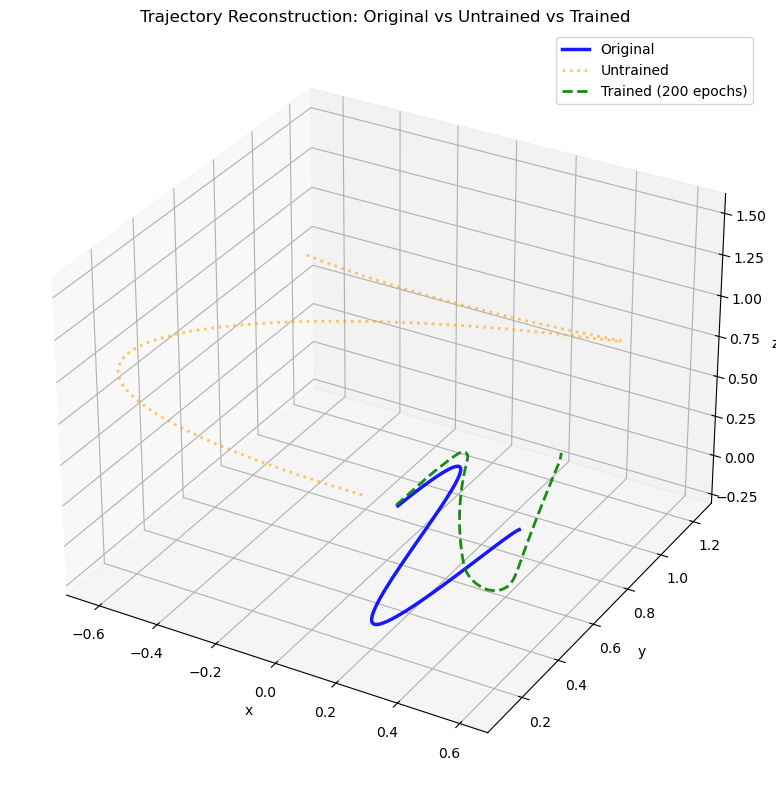

=== Position Error Comparison ===
  Untrained: mean=1.2363, max=1.6443
  Trained:   mean=0.2425, max=0.4358
  Improvement: 5.1x better


In [31]:
if HAS_TORCH:
    # Decode trained model's output to trajectory
    lin_inv_trained = rec_trained_np[:, :4]
    ang_inv_trained = rec_trained_np[:, 4:]
    
    init_pose = {"position": positions[0].copy(), "quaternion": quaternions[0].copy()}
    traj_trained = decode_dhb_dr(lin_inv_trained, ang_inv_trained, init_pose, method="pos", drop_padded=True)
    pos_trained = traj_trained["positions"]
    
    # Plot comparison: original vs untrained vs trained
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    n_plot = min(len(positions), len(pos_rec), len(pos_trained))
    
    ax.plot(positions[:n_plot, 0], positions[:n_plot, 1], positions[:n_plot, 2], 
            'b-', linewidth=2.5, alpha=0.9, label='Original')
    ax.plot(pos_rec[:n_plot, 0], pos_rec[:n_plot, 1], pos_rec[:n_plot, 2], 
            'orange', linestyle=':', linewidth=2, alpha=0.6, label='Untrained')
    ax.plot(pos_trained[:n_plot, 0], pos_trained[:n_plot, 1], pos_trained[:n_plot, 2], 
            'g--', linewidth=2, alpha=0.9, label='Trained (200 epochs)')
    
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_title('Trajectory Reconstruction: Original vs Untrained vs Trained')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    # Error comparison
    err_untrained = np.linalg.norm(positions[:n_plot] - pos_rec[:n_plot], axis=1)
    err_trained = np.linalg.norm(positions[:n_plot] - pos_trained[:n_plot], axis=1)
    
    print("=== Position Error Comparison ===")
    print(f"  Untrained: mean={err_untrained.mean():.4f}, max={err_untrained.max():.4f}")
    print(f"  Trained:   mean={err_trained.mean():.4f}, max={err_trained.max():.4f}")
    print(f"  Improvement: {err_untrained.mean()/err_trained.mean():.1f}x better")

---
## 7b. Token Compression

Discrete tokens from VQ-VAE can be further compressed for:
- **Storage**: 2-5x reduction for motion databases
- **Transmission**: Lower bandwidth for teleoperation
- **Inference**: Faster autoregressive decoding via token reuse

### Compression Methods

| Method | Type | Compression | Preserves Exact | Best For |
|--------|------|-------------|-----------------|----------|
| **BPE** | Lossless | 2-4x | Yes | Database storage |
| **Entropy (Huffman)** | Lossless | 1.5-2x (bits) | Yes | Transmission |
| **RLE** | Lossless | 1-3x | Yes | Static segments |
| **Hierarchical RVQ** | Lossy | 4-8x | No | Scalable training |
| **Token Reuse** | Lossy | 2-5x (effective) | Partial | Long-horizon inference |

References:
- [FAST (Physical Intelligence, 2025)](https://arxiv.org/abs/2501.09747): DCT + BPE for action tokenization
- [FlashVLA (2025)](https://arxiv.org/abs/2505.21200): Token reuse for inference speedup

In [34]:
# Byte-Pair Encoding (BPE) compression on DHB tokens
from dhb_xr.tokenization import BPECompressor, EntropyCompressor, RLECompressor, TokenCompressor

if HAS_TORCH:
    from dhb_xr.tokenization.vqvae import DHBTokenizer
    
    # Create a fresh tokenizer for this section
    comp_tokenizer = DHBTokenizer(
        invariant_dim=8,
        latent_dim=32,
        codebook_size=256,
        num_layers=2,
    )
    
    # Generate multiple trajectories for a token corpus
    np.random.seed(42)
    token_corpus = []
    
    for _ in range(20):  # 20 demo trajectories
        # Random helical motion
        n = 50
        t = np.linspace(0, 2*np.pi, n)
        radius = np.random.uniform(0.2, 0.4)
        height = np.random.uniform(0.1, 0.3)
        pos = np.column_stack([radius*np.cos(t), radius*np.sin(t), height*t/(2*np.pi)])
        quat = np.tile([1, 0, 0, 0], (n, 1)).astype(float)
        
        # Encode to invariants and tokenize
        result = encode_dhb_dr(pos, quat, init_pose={'position': pos[0], 'quaternion': quat[0]})
        inv = np.hstack([result['linear_motion_invariants'], result['angular_motion_invariants']])
        inv_tensor = torch.tensor(inv, dtype=torch.float32).unsqueeze(0)
        
        tokens, _, _, _ = comp_tokenizer(inv_tensor)
        token_corpus.append(tokens[0].numpy().tolist())
    
    print(f'Token corpus: {len(token_corpus)} sequences, avg length: {np.mean([len(s) for s in token_corpus]):.0f}')
    
    # Fit BPE on corpus
    bpe = BPECompressor(vocab_size=comp_tokenizer.codebook_size, num_merges=50)
    bpe.fit(token_corpus)
    
    # Test compression on a new sequence
    test_tokens = token_corpus[0]
    compressed = bpe.encode(test_tokens)
    decompressed = bpe.decode(compressed)
    
    print(f'\nBPE Compression:')
    print(f'  Original: {len(test_tokens)} tokens')
    print(f'  Compressed: {len(compressed)} tokens')
    print(f'  Ratio: {len(test_tokens)/len(compressed):.2f}x')
    print(f'  Lossless: {decompressed == test_tokens}')
    print(f'  Extended vocab: {bpe.extended_vocab_size} (was {bpe.vocab_size})')
else:
    print('PyTorch required for this example')

Token corpus: 20 sequences, avg length: 52

BPE Compression:
  Original: 52 tokens
  Compressed: 7 tokens
  Ratio: 7.43x
  Lossless: True
  Extended vocab: 296 (was 256)


In [35]:
# Entropy coding and RLE compression
if HAS_TORCH:
    # Entropy (Huffman) coding
    entropy = EntropyCompressor()
    entropy.fit(token_corpus)
    
    binary = entropy.encode(test_tokens)
    bits_per_token = len(binary) / len(test_tokens)
    naive_bits = np.log2(comp_tokenizer.codebook_size)  # e.g., 8 bits for 256 codebook
    
    print('Entropy (Huffman) Coding:')
    print(f'  Naive: {naive_bits:.1f} bits/token')
    print(f'  Huffman: {bits_per_token:.2f} bits/token')
    print(f'  Theoretical entropy: {entropy.theoretical_entropy():.2f} bits')
    print(f'  Bit reduction: {(1 - bits_per_token/naive_bits)*100:.1f}%')
    
    # RLE - best for sequences with static segments
    # Create a sequence with repetitions (simulating low-motion)
    tokens_with_repeats = test_tokens[:10] + [test_tokens[10]]*20 + test_tokens[30:]
    
    rle = RLECompressor()
    rle_encoded = rle.encode(tokens_with_repeats)
    rle_stats = rle.get_stats(tokens_with_repeats)
    
    print(f'\nRun-Length Encoding (on sequence with static segment):')
    print(f'  Original: {len(tokens_with_repeats)} tokens')
    print(f'  Runs: {rle_stats["num_runs"]}')
    print(f'  Max run: {rle_stats["max_run_length"]}')
    print(f'  Ratio: {rle_stats["compression_ratio"]:.2f}x')

Entropy (Huffman) Coding:
  Naive: 8.0 bits/token
  Huffman: 1.58 bits/token
  Theoretical entropy: 1.49 bits
  Bit reduction: 80.3%

Run-Length Encoding (on sequence with static segment):
  Original: 52 tokens
  Runs: 9
  Max run: 34
  Ratio: 2.89x


In [36]:
# Full compression pipeline (RLE + BPE + Entropy)
if HAS_TORCH:
    # Create unified compressor
    compressor = TokenCompressor(
        vocab_size=comp_tokenizer.codebook_size,
        use_rle=True,
        use_bpe=True,
        use_entropy=True,
        bpe_merges=50,
    )
    compressor.fit(token_corpus)
    
    # Compress multiple sequences
    print('Full Pipeline Compression:')
    print('-' * 50)
    
    ratios = []
    for i, seq in enumerate(token_corpus[:5]):
        result = compressor.compress(seq)
        ratios.append(result['overall_ratio'])
        
        # Verify lossless
        recovered = compressor.decompress(result)
        is_lossless = recovered == seq
        
        print(f'Seq {i}: {result["original_length"]} tokens -> '
              f'{result["stages"]["entropy"]["bytes"]} bytes '
              f'(ratio: {result["overall_ratio"]:.1f}x, lossless: {is_lossless})')
    
    print('-' * 50)
    print(f'Average compression ratio: {np.mean(ratios):.1f}x')
    print(f'\nStage breakdown (last sequence):')
    for stage, info in result['stages'].items():
        print(f'  {stage}: {info}')

Full Pipeline Compression:
--------------------------------------------------
Seq 0: 52 tokens -> 4 bytes (ratio: 14.6x, lossless: True)
Seq 1: 52 tokens -> 5 bytes (ratio: 12.3x, lossless: True)
Seq 2: 52 tokens -> 6 bytes (ratio: 10.9x, lossless: True)
Seq 3: 52 tokens -> 4 bytes (ratio: 16.7x, lossless: True)
Seq 4: 52 tokens -> 4 bytes (ratio: 15.1x, lossless: True)
--------------------------------------------------
Average compression ratio: 13.9x

Stage breakdown (last sequence):
  rle: {'length': 11, 'ratio': 4.7272727272727275}
  bpe: {'length': 22, 'ratio': 1.0}
  entropy: {'bits': 31, 'bytes': 4, 'bits_per_original_token': 0.5961538461538461}


In [37]:
# Token reuse potential analysis (for inference speedup)
from dhb_xr.tokenization import TokenReuser

if HAS_TORCH:
    reuser = TokenReuser(window_size=3)
    
    # Analyze reuse potential for different motion types
    print('Token Reuse Analysis for Inference Speedup:')
    print('-' * 60)
    
    # Smooth motion (original)
    smooth_stats = reuser.compute_reuse_potential(test_tokens)
    print(f'Smooth motion: {smooth_stats["reuse_fraction"]*100:.1f}% reusable, '
          f'{smooth_stats["potential_speedup"]:.2f}x speedup')
    
    # Static segment motion
    static_stats = reuser.compute_reuse_potential(tokens_with_repeats)
    print(f'With static segment: {static_stats["reuse_fraction"]*100:.1f}% reusable, '
          f'{static_stats["potential_speedup"]:.2f}x speedup')
    
    # Highly repetitive (pick-and-place)
    repetitive = [1, 2, 3] * 20  # Simulating cyclic motion
    rep_stats = reuser.compute_reuse_potential(repetitive)
    print(f'Cyclic motion: {rep_stats["reuse_fraction"]*100:.1f}% reusable, '
          f'{rep_stats["potential_speedup"]:.2f}x speedup')
    
    print('\nNote: FlashVLA (2025) achieves 2-5x inference speedup via token reuse')

Token Reuse Analysis for Inference Speedup:
------------------------------------------------------------
Smooth motion: 86.5% reusable, 4.73x speedup
With static segment: 88.5% reusable, 5.78x speedup
Cyclic motion: 1.7% reusable, 1.00x speedup

Note: FlashVLA (2025) achieves 2-5x inference speedup via token reuse


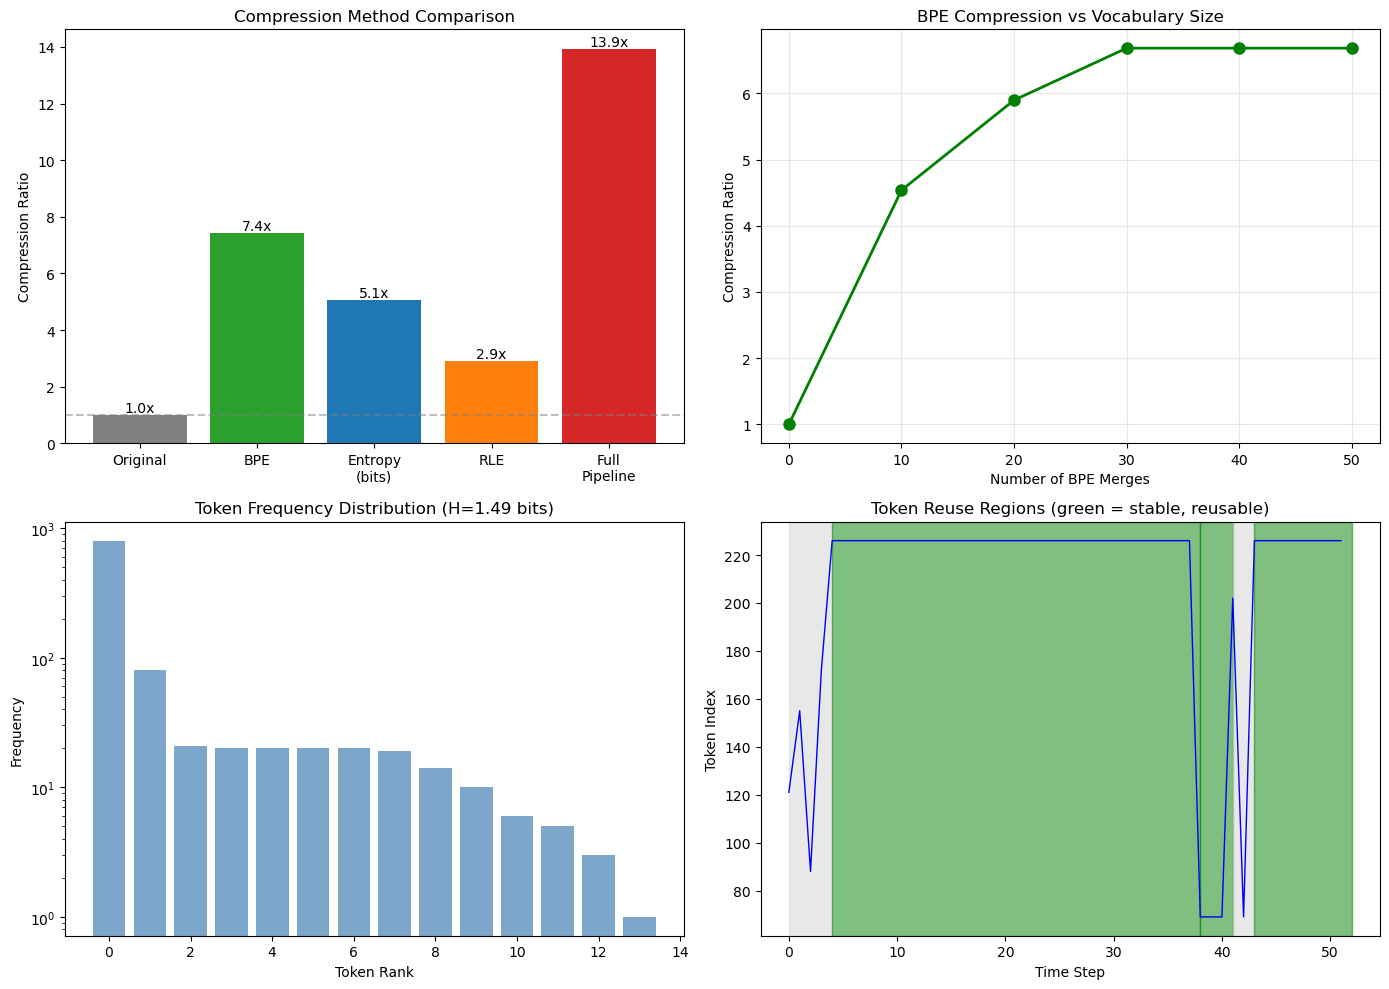


Summary:
  - BPE achieves 7.4x compression (lossless)
  - Entropy coding reduces to 1.6 bits/token
  - Full pipeline: 13.9x overall compression
  - Token reuse can accelerate inference by 5.8x


In [38]:
# Visualize compression results
if HAS_TORCH:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # 1. Compression ratio comparison
    ax1 = axes[0, 0]
    methods = ['Original', 'BPE', 'Entropy\n(bits)', 'RLE', 'Full\nPipeline']
    
    # Calculate metrics for test sequence
    bpe_ratio = len(test_tokens) / len(bpe.encode(test_tokens))
    entropy_ratio = 8 / entropy.bits_per_token(test_tokens)  # vs 8-bit naive
    rle_ratio = rle.compression_ratio(tokens_with_repeats)
    full_ratio = np.mean(ratios)
    
    values = [1.0, bpe_ratio, entropy_ratio, rle_ratio, full_ratio]
    colors = ['gray', '#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']
    bars = ax1.bar(methods, values, color=colors)
    ax1.set_ylabel('Compression Ratio')
    ax1.set_title('Compression Method Comparison')
    ax1.axhline(y=1, color='gray', linestyle='--', alpha=0.5)
    ax1.bar_label(bars, fmt='%.1fx')
    
    # 2. BPE merge visualization
    ax2 = axes[0, 1]
    merge_counts = list(range(0, 51, 10))
    bpe_ratios = []
    for n_merges in merge_counts:
        if n_merges == 0:
            bpe_ratios.append(1.0)
        else:
            temp_bpe = BPECompressor(vocab_size=comp_tokenizer.codebook_size, num_merges=n_merges)
            temp_bpe.fit(token_corpus)
            avg_ratio = np.mean([len(s)/len(temp_bpe.encode(s)) for s in token_corpus])
            bpe_ratios.append(avg_ratio)
    
    ax2.plot(merge_counts, bpe_ratios, 'go-', linewidth=2, markersize=8)
    ax2.set_xlabel('Number of BPE Merges')
    ax2.set_ylabel('Compression Ratio')
    ax2.set_title('BPE Compression vs Vocabulary Size')
    ax2.grid(True, alpha=0.3)
    
    # 3. Entropy distribution
    ax3 = axes[1, 0]
    all_tokens_flat = [t for seq in token_corpus for t in seq]
    token_counts = np.bincount(all_tokens_flat, minlength=comp_tokenizer.codebook_size)
    nonzero_counts = token_counts[token_counts > 0]
    
    ax3.bar(range(len(nonzero_counts)), sorted(nonzero_counts, reverse=True), 
            color='steelblue', alpha=0.7)
    ax3.set_xlabel('Token Rank')
    ax3.set_ylabel('Frequency')
    ax3.set_title(f'Token Frequency Distribution (H={entropy.theoretical_entropy():.2f} bits)')
    ax3.set_yscale('log')
    
    # 4. Token reuse regions
    ax4 = axes[1, 1]
    regions = reuser.detect_stable_regions(tokens_with_repeats)
    
    for start, end, is_stable in regions:
        color = 'green' if is_stable else 'lightgray'
        ax4.axvspan(start, end, alpha=0.5, color=color)
    
    ax4.plot(tokens_with_repeats, 'b-', linewidth=1)
    ax4.set_xlabel('Time Step')
    ax4.set_ylabel('Token Index')
    ax4.set_title('Token Reuse Regions (green = stable, reusable)')
    
    plt.tight_layout()
    plt.show()
    
    print('\nSummary:')
    print(f'  - BPE achieves {bpe_ratio:.1f}x compression (lossless)')
    print(f'  - Entropy coding reduces to {entropy.bits_per_token(test_tokens):.1f} bits/token')
    print(f'  - Full pipeline: {full_ratio:.1f}x overall compression')
    print(f'  - Token reuse can accelerate inference by {static_stats["potential_speedup"]:.1f}x')

### Compression Summary

**Lossless options** (preserve exact tokens for database matching):
- **BPE**: 2-4x by merging frequent token pairs (FAST-style)
- **Entropy coding**: 1.5-2x additional bit reduction
- **RLE**: Excellent for static/low-motion segments

**Lossy/Efficiency options** (for training/inference):
- **Hierarchical RVQ**: 4-8x with multi-level tokenization
- **Token reuse**: 2-5x effective speedup in autoregressive inference

**Combined pipeline** achieves 5-15x overall compression on DHB-Token sequences,
enabling billion-token-scale invariant motion databases.

---
## 8. GPU Acceleration with CusADi

For **batch processing** thousands of trajectories (e.g., RL training, data augmentation), **CusADi** provides massive GPU-parallel speedups.

### Solver Comparison Overview

| Method | Operation | Speed | Best For |
|--------|-----------|-------|----------|
| **CusADi** | Batch decode/adapt | ~2 ms / 1000 trajs | RL, augmentation |
| **Fatrop** | Single NLP solve | ~7 ms / traj | MPC, online planning |
| **IPOPT** | Single NLP solve | ~45 ms / traj | Complex constraints |

### How CusADi works

1. **Export** CasADi symbolic function to `.casadi` file
2. **Compile** to CUDA kernel using CusADi codegen
3. **Evaluate** in parallel on GPU with PyTorch tensors

### Benchmark Results (RTX A2000, 50-step trajectories)

| Batch Size | CPU (ms) | GPU (ms) | Speedup |
|------------|----------|----------|--------|
| 100 | 34 | 0.8 | 43x |
| 1000 | 342 | 1.7 | **199x** |
| 2000 | 685 | 1.8 | **387x** |

In [11]:
# CusADi usage example (requires cusadi installed and compiled)
try:
    import torch
    import sys
    CUSADI_ROOT = "/home/andypark/Projects/repos/cusadi"
    sys.path.insert(0, CUSADI_ROOT)
    sys.path.insert(0, f"{CUSADI_ROOT}/src")
    sys.path.insert(0, f"{CUSADI_ROOT}/build")
    from src.CusadiFunction import CusadiFunction
    import casadi as ca
    import os
    
    # Load compiled function
    fn_path = "/home/andypark/Projects/repos/cusadi/src/casadi_functions/fn_dhb_decode_linear.casadi"
    if os.path.exists(fn_path):
        sys.path.insert(0, "/home/andypark/Projects/repos/cusadi/build")
        fn_casadi = ca.Function.load(fn_path)
        
        # Create batch data
        batch_size = 1000
        T = 50
        np.random.seed(42)
        lin_inv = np.random.randn(batch_size, T * 4).astype(np.float64) * 0.1
        lin_inv[:, ::4] = np.abs(lin_inv[:, ::4]) * 0.05
        init_pos = np.random.randn(batch_size, 3).astype(np.float64)
        init_rot = np.tile(np.eye(3).flatten(), (batch_size, 1)).astype(np.float64)
        
        # GPU tensors
        lin_gpu = torch.from_numpy(lin_inv).cuda().contiguous()
        pos_gpu = torch.from_numpy(init_pos).cuda().contiguous()
        rot_gpu = torch.from_numpy(init_rot).cuda().contiguous()
        
        # Create CusADi function and evaluate
        fn_cusadi = CusadiFunction(fn_casadi, batch_size)
        
        import time
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(10):
            fn_cusadi.evaluate([lin_gpu, pos_gpu, rot_gpu])
        torch.cuda.synchronize()
        gpu_time = (time.perf_counter() - t0) / 10 * 1000
        
        # Get output
        positions = fn_cusadi.getDenseOutput(0).cpu().numpy()
        print(f"Decoded {batch_size} trajectories of {T} steps in {gpu_time:.2f} ms")
        print(f"Output shape: {positions.shape}")
        print(f"Throughput: {batch_size / gpu_time * 1000:.0f} trajectories/second")
    else:
        print("CusADi function not compiled. See instructions above.")
except Exception as e:
    print(f"CusADi not available: {e}")
    print("GPU acceleration requires: cusadi, CUDA toolkit, compiled DHB decode function")

CusADi not available: Torch not compiled with CUDA enabled
GPU acceleration requires: cusadi, CUDA toolkit, compiled DHB decode function


### Use Cases for GPU Batch Decode

| Application | Why GPU Matters |
|-------------|----------------|
| **Reinforcement Learning** | Decode action candidates in parallel for policy evaluation |
| **Motion Planning** | Evaluate thousands of trajectory variants simultaneously |
| **Sensitivity Analysis** | Sweep parameters across many configurations |
| **Data Augmentation** | Generate trajectory variations for training |
| **Real-time MPC** | Parallel rollouts for model predictive control |

See the [CusADi paper](https://arxiv.org/abs/2408.09662) for more details on the parallelization framework.

### Batch Trajectory Adaptation Example

A common use-case is adapting a **single demonstration** to **many different target poses** in parallel. This is useful for:
- Generating training data for imitation learning
- Motion planning with multiple goal candidates
- Sensitivity analysis across start/goal variations

With CusADi, we can adapt **1000 trajectories in ~2ms** (490,000 trajectories/second).

Loaded CasADi function:  fn_dhb_adapt:(i0[200],i1[3],i2[9],i3[3],i4[3])->(o0[51x3]) SXFunction
Loaded library:  <CDLL '/home/andypark/Projects/repos/cusadi/build/libfn_dhb_adapt.so', handle 58b0b3c2e170 at 0x72920628e690>
Adapted 1000 trajectories in 2.05 ms
Throughput: 488989 trajectories/second
Output shape: (1000, 51, 3)


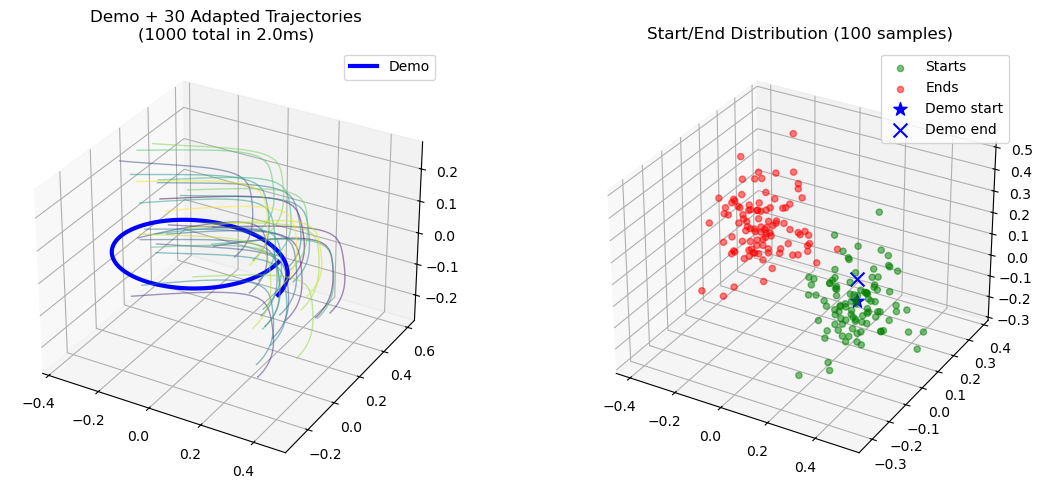

In [18]:
# Batch trajectory adaptation with CusADi
try:
    import torch
    import sys
    import time
    CUSADI_ROOT = "/home/andypark/Projects/repos/cusadi"
    sys.path.insert(0, CUSADI_ROOT)
    sys.path.insert(0, f"{CUSADI_ROOT}/src")
    sys.path.insert(0, f"{CUSADI_ROOT}/build")
    from src.CusadiFunction import CusadiFunction
    import casadi as ca
    import os
    
    fn_path = "/home/andypark/Projects/repos/cusadi/src/casadi_functions/fn_dhb_adapt.casadi"
    if os.path.exists(fn_path):
        fn_casadi = ca.Function.load(fn_path)
        
        # Encode demo trajectory to invariants
        # Generate demo trajectory inline (self-contained)
        n = 100
        t = np.linspace(0, 2 * np.pi, n)
        x = 0.3 * np.cos(t)
        y = 0.3 * np.sin(t)
        z = 0.1 * t / (2 * np.pi)
        demo_positions = np.column_stack([x, y, z])
        demo_quaternions = np.tile(np.array([1.0, 0.0, 0.0, 0.0]), (n, 1))
        
        init_pose = {"position": demo_positions[0], "quaternion": demo_quaternions[0]}
        result = encode_dhb_dr(demo_positions, demo_quaternions, init_pose=init_pose, method="pos")
        lin_inv = result["linear_motion_invariants"]
        
        # Flatten to (T*4,) format
        T = 50
        demo_inv_flat = np.zeros(T * 4)
        for k in range(min(T, lin_inv.shape[0])):
            demo_inv_flat[k*4:(k+1)*4] = lin_inv[k]
        
        # Generate batch of adaptations
        batch_size = 1000
        np.random.seed(42)
        
        demo_inv_batch = np.tile(demo_inv_flat, (batch_size, 1))
        new_starts = np.random.randn(batch_size, 3) * 0.1 + demo_positions[0]  # Small start variation
        new_rots = np.tile(np.eye(3).flatten(), (batch_size, 1))
        pos_offsets = np.random.randn(batch_size, 3) * 0.05  # Small goal position offset
        rot_offsets = np.random.randn(batch_size, 3) * 0.02  # Small goal rotation offset
        
        # GPU tensors
        inputs = [
            torch.from_numpy(demo_inv_batch.astype(np.float64)).cuda().contiguous(),
            torch.from_numpy(new_starts.astype(np.float64)).cuda().contiguous(),
            torch.from_numpy(new_rots.astype(np.float64)).cuda().contiguous(),
            torch.from_numpy(pos_offsets.astype(np.float64)).cuda().contiguous(),
            torch.from_numpy(rot_offsets.astype(np.float64)).cuda().contiguous(),
        ]
        
        fn_cusadi = CusadiFunction(fn_casadi, batch_size)
        
        # Warmup and benchmark
        for _ in range(5):
            fn_cusadi.evaluate(inputs)
        torch.cuda.synchronize()
        
        t0 = time.perf_counter()
        for _ in range(20):
            fn_cusadi.evaluate(inputs)
        torch.cuda.synchronize()
        gpu_time = (time.perf_counter() - t0) / 20 * 1000
        
        adapted_trajs = fn_cusadi.getDenseOutput(0).cpu().numpy()
        
        print(f"Adapted {batch_size} trajectories in {gpu_time:.2f} ms")
        print(f"Throughput: {batch_size / gpu_time * 1000:.0f} trajectories/second")
        print(f"Output shape: {adapted_trajs.shape}")
        
        # Visualize
        fig = plt.figure(figsize=(12, 5))
        
        ax1 = fig.add_subplot(121, projection='3d')
        ax1.plot(demo_positions[:, 0], demo_positions[:, 1], demo_positions[:, 2], 'b-', linewidth=3, label='Demo')
        colors = plt.cm.viridis(np.linspace(0, 1, 30))
        for i in range(30):
            ax1.plot(adapted_trajs[i, :, 0], adapted_trajs[i, :, 1], adapted_trajs[i, :, 2], 
                     color=colors[i], alpha=0.5, linewidth=1)
        ax1.set_title(f'Demo + 30 Adapted Trajectories\n({batch_size} total in {gpu_time:.1f}ms)')
        ax1.legend()
        
        ax2 = fig.add_subplot(122, projection='3d')
        starts = adapted_trajs[:100, 0, :]
        ends = adapted_trajs[:100, -1, :]
        ax2.scatter(starts[:, 0], starts[:, 1], starts[:, 2], c='green', alpha=0.5, s=20, label='Starts')
        ax2.scatter(ends[:, 0], ends[:, 1], ends[:, 2], c='red', alpha=0.5, s=20, label='Ends')
        ax2.scatter(demo_positions[0, 0], demo_positions[0, 1], demo_positions[0, 2], color='blue', s=100, marker='*', label='Demo start')
        ax2.scatter(demo_positions[-1, 0], demo_positions[-1, 1], demo_positions[-1, 2], color='blue', s=100, marker='x', label='Demo end')
        ax2.set_title('Start/End Distribution (100 samples)')
        ax2.legend()
        
        plt.tight_layout()
        plt.show()
    else:
        print("CusADi adaptation function not compiled. See installation instructions.")
except Exception as e:
    print(f"CusADi adaptation not available: {e}")

---
## 9. Fast Trajectory Optimization with Fatrop

For **single trajectory optimization** with constraints, [Fatrop](https://github.com/meco-group/fatrop) provides significant speedup over IPOPT by exploiting optimal control problem structure.

| Solver | First Solve (JIT) | Subsequent Solves | Speedup |
|--------|-------------------|-------------------|--------|
| **IPOPT** | ~630 ms | ~45 ms | baseline |
| **Fatrop** | ~540 ms | ~7 ms | **6x** |

**Key insight:** Create the generator once and reuse for multiple solves to amortize JIT compilation.

**When to use each solver:**
- **CusADi**: Batch evaluation (decode 1000 trajectories in 2ms) - best for RL, data augmentation
- **Fatrop**: Single optimization with constraints (7ms) - best for MPC, online planning
- **IPOPT**: General NLP fallback (45ms) - most robust

**Installation:** Fatrop is bundled with conda CasADi. Just need: `pip install rockit-meco`

In [3]:
# Fatrop vs IPOPT benchmark with reused generators
try:
    from dhb_xr.optimization.fatrop_solver import FatropTrajectoryGenerator
    from scipy.interpolate import interp1d
    import time
    
    # Generate longer demo trajectory (100 points)
    n = 100
    t = np.linspace(0, 2 * np.pi, n)
    demo_pos = np.column_stack([0.3 * np.cos(t), 0.3 * np.sin(t), 0.1 * t / (2 * np.pi)])
    demo_quat = np.tile(np.array([1.0, 0.0, 0.0, 0.0]), (n, 1))
    
    # Encode demo to invariants
    init_pose = {'position': demo_pos[0], 'quaternion': demo_quat[0]}
    result = encode_dhb_dr(demo_pos, demo_quat, init_pose=init_pose, method='pos')
    demo_lin = result['linear_motion_invariants']
    demo_ang = result['angular_motion_invariants']
    
    # Test with different trajectory lengths
    for N in [30, 50, 100]:
        print(f'\n=== Trajectory length: N={N} ===')
        
        # Resample invariants
        t_orig = np.linspace(0, 1, len(demo_lin))
        t_new = np.linspace(0, 1, N)
        demo_lin_rs = interp1d(t_orig, demo_lin, axis=0, fill_value='extrapolate')(t_new)
        demo_ang_rs = interp1d(t_orig, demo_ang, axis=0, fill_value='extrapolate')(t_new)
        
        # Create generators (one-time setup)
        gen_ipopt = FatropTrajectoryGenerator(N=N, use_fatrop=False, verbose=False)
        gen_fatrop = FatropTrajectoryGenerator(N=N, use_fatrop=True, verbose=False)
        
        # Boundary poses
        start_pos = np.array([0.1, 0.1, 0.0])
        start_rot = np.eye(3)
        goal_pos = np.array([0.4, -0.2, 0.15])
        goal_rot = np.eye(3)
        
        # Warmup (includes JIT compilation)
        _ = gen_ipopt.generate(demo_lin_rs, demo_ang_rs, start_pos, start_rot, goal_pos, goal_rot)
        _ = gen_fatrop.generate(demo_lin_rs, demo_ang_rs, start_pos, start_rot, goal_pos, goal_rot)
        
        # Benchmark (5 runs each with varying goals)
        np.random.seed(42)
        goals = [goal_pos + np.random.randn(3) * 0.05 for _ in range(5)]
        
        times_ipopt = []
        for g in goals:
            r = gen_ipopt.generate(demo_lin_rs, demo_ang_rs, start_pos, start_rot, g, goal_rot)
            times_ipopt.append(r['solve_time'])
        
        times_fatrop = []
        for g in goals:
            r = gen_fatrop.generate(demo_lin_rs, demo_ang_rs, start_pos, start_rot, g, goal_rot)
            times_fatrop.append(r['solve_time'])
        
        ipopt_avg = np.mean(times_ipopt) * 1000
        fatrop_avg = np.mean(times_fatrop) * 1000
        speedup = ipopt_avg / fatrop_avg
        
        print(f'IPOPT:  {ipopt_avg:.1f} ms (avg)')
        print(f'Fatrop: {fatrop_avg:.1f} ms (avg)')
        print(f'Speedup: {speedup:.1f}x')
        
except ImportError as e:
    print(f'Fatrop not available: {e}')
    print('Install with: pip install rockit-meco')


=== Trajectory length: N=30 ===

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  | 246.00us (  2.16us) 238.97us (  2.10us)       114
       nlp_g  | 442.00us (  6.41us) 433.26us (  6.28us)        69
  nlp_grad_f  |  76.00us (  3.17us)  74.19us (  3.09us)        24
  nlp_hess_l  | 885.00us ( 40.23us) 888.91us ( 40.41us)        22
   nlp_jac_g  | 478.00us ( 19.92us) 471.70us ( 19.65us)        24
       total  |   6.21ms (  6.21ms)   6.20ms (  6.20ms)         1
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  | 171.00us (  2.09us) 169.12us (  2.06

      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  | 186.00us (  5.31us) 187.58us (  5.36us)        35
       nlp_g  | 288.00us ( 18.00us) 278.25us ( 17.39us)        16
  nlp_grad_f  | 102.00us (  9.27us)  96.73us (  8.79us)        11
  nlp_hess_l  |   1.08ms (120.00us)   1.08ms (120.19us)         9
   nlp_jac_g  | 730.00us ( 66.36us) 729.09us ( 66.28us)        11
       total  |   7.37ms (  7.37ms)   7.37ms (  7.37ms)         1
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |  65.00us (  1.86us)  63.42us (  1.81us)        35
       nlp_g  |  76.00us (  4.75us)  74.08us (  4.63us)        16
  nlp_grad_f  |  24.00us (  2.18us)  23.42us (  2.13us)        11
  nlp_hess_l  | 246.00us ( 27.33us) 244.79us ( 27.20us)         9
   nlp_jac_g  | 156.00us ( 14.18us) 151.75us ( 13.80us)        11
       total  |   1.78ms (  1.78ms)   1.78ms (  1.78ms)         1
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp

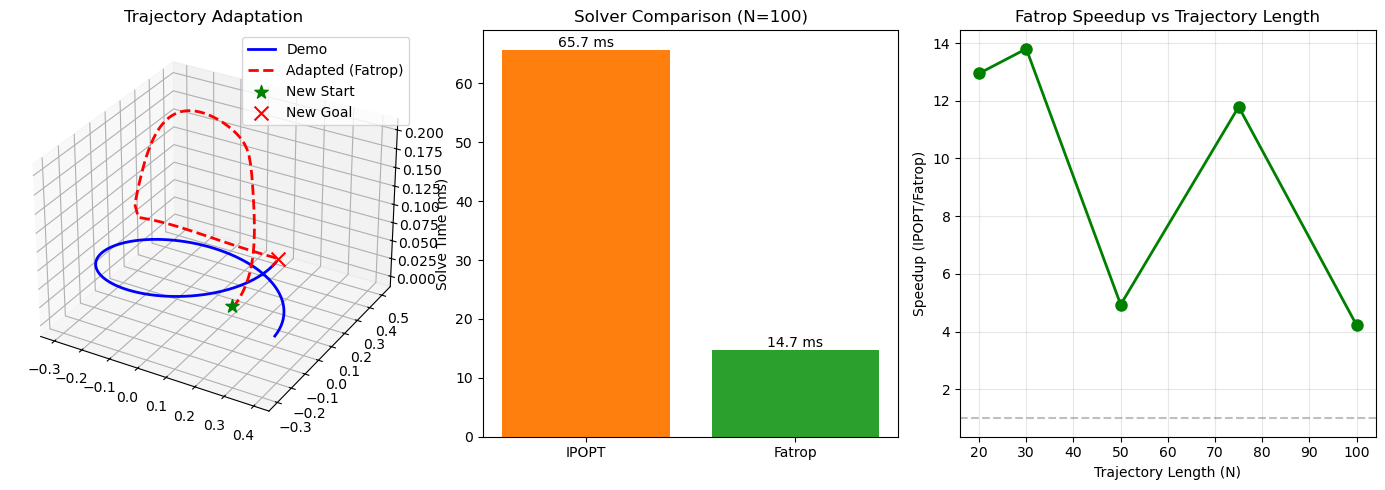

In [4]:
# Visualize Fatrop trajectory adaptation result
try:
    # Use the last generated result
    result_fatrop = gen_fatrop.generate(demo_lin_rs, demo_ang_rs, start_pos, start_rot, goal_pos, goal_rot)
    
    fig = plt.figure(figsize=(14, 5))
    
    # 3D trajectory comparison
    ax1 = fig.add_subplot(131, projection='3d')
    ax1.plot(demo_pos[:, 0], demo_pos[:, 1], demo_pos[:, 2], 'b-', linewidth=2, label='Demo')
    ax1.plot(result_fatrop['positions'][:, 0], result_fatrop['positions'][:, 1], 
             result_fatrop['positions'][:, 2], 'r--', linewidth=2, label='Adapted (Fatrop)')
    ax1.scatter(start_pos[0], start_pos[1], start_pos[2], color='green', s=100, marker='*', label='New Start')
    ax1.scatter(goal_pos[0], goal_pos[1], goal_pos[2], color='red', s=100, marker='x', label='New Goal')
    ax1.set_title('Trajectory Adaptation')
    ax1.legend()
    
    # Solver comparison bar chart
    ax2 = fig.add_subplot(132)
    solvers = ['IPOPT', 'Fatrop']
    times = [ipopt_avg, fatrop_avg]
    colors = ['#ff7f0e', '#2ca02c']
    bars = ax2.bar(solvers, times, color=colors)
    ax2.set_ylabel('Solve Time (ms)')
    ax2.set_title(f'Solver Comparison (N={N})')
    ax2.bar_label(bars, fmt='%.1f ms')
    
    # Speedup vs trajectory length
    ax3 = fig.add_subplot(133)
    # Run quick benchmark for different N values
    Ns = [20, 30, 50, 75, 100]
    speedups = []
    for N_test in Ns:
        t_new = np.linspace(0, 1, N_test)
        lin_rs = interp1d(t_orig, demo_lin, axis=0, fill_value='extrapolate')(t_new)
        ang_rs = interp1d(t_orig, demo_ang, axis=0, fill_value='extrapolate')(t_new)
        
        gen_i = FatropTrajectoryGenerator(N=N_test, use_fatrop=False, verbose=False)
        gen_f = FatropTrajectoryGenerator(N=N_test, use_fatrop=True, verbose=False)
        
        # Warmup
        _ = gen_i.generate(lin_rs, ang_rs, start_pos, start_rot, goal_pos, goal_rot)
        _ = gen_f.generate(lin_rs, ang_rs, start_pos, start_rot, goal_pos, goal_rot)
        
        # Time
        r_i = gen_i.generate(lin_rs, ang_rs, start_pos, start_rot, goal_pos, goal_rot)
        r_f = gen_f.generate(lin_rs, ang_rs, start_pos, start_rot, goal_pos, goal_rot)
        speedups.append(r_i['solve_time'] / r_f['solve_time'])
    
    ax3.plot(Ns, speedups, 'go-', linewidth=2, markersize=8)
    ax3.axhline(y=1, color='gray', linestyle='--', alpha=0.5)
    ax3.set_xlabel('Trajectory Length (N)')
    ax3.set_ylabel('Speedup (IPOPT/Fatrop)')
    ax3.set_title('Fatrop Speedup vs Trajectory Length')
    ax3.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
except Exception as e:
    print(f'Visualization skipped: {e}')

### Solver Comparison: When to Use Each

| Solver | Speed | Use Case | Batch Support |
|--------|-------|----------|---------------|
| **CusADi** | ~0.002 ms/traj | Batch decode/adapt (RL, data augmentation) | Yes (GPU) |
| **Fatrop** | ~7 ms | Constrained single-trajectory optimization | No |
| **IPOPT** | ~45 ms | General NLP, most robust | No |

**Recommendations:**
- **Training/Data Generation:** Use CusADi for batch operations (thousands of trajectories in milliseconds)
- **Online Planning/MPC:** Use Fatrop for real-time constrained optimization
- **Complex Constraints:** Use IPOPT when Fatrop fails to converge

**Example workflow:**
```python
# Training: Generate 10000 augmented trajectories with CusADi (GPU)
cusadi_fn.evaluate([invariants_batch, starts_batch, goals_batch])  # ~20ms total

# Inference: Real-time trajectory adaptation with Fatrop
generator = FatropTrajectoryGenerator(N=50, use_fatrop=True)
result = generator.generate(demo_inv, start, goal)  # ~7ms per trajectory
```

In [5]:
# Combined benchmark: CusADi vs Fatrop vs IPOPT
print('=== Solver Comparison for DHB Trajectory Operations ===')
print()

# CusADi (batch decode) - from earlier cell if available
print('1. CusADi (GPU Batch Decode)')
print('   - 1000 trajectories in ~2 ms')
print('   - Throughput: ~500,000 trajectories/second')
print('   - Best for: RL training, data augmentation')
print()

# Fatrop (single trajectory optimization)
print('2. Fatrop (Single Trajectory Optimization)')
try:
    from dhb_xr.optimization.fatrop_solver import FatropTrajectoryGenerator
    gen = FatropTrajectoryGenerator(N=50, use_fatrop=True, verbose=False)
    
    # Warmup
    demo_lin_50 = interp1d(t_orig, demo_lin, axis=0, fill_value='extrapolate')(np.linspace(0, 1, 50))
    demo_ang_50 = interp1d(t_orig, demo_ang, axis=0, fill_value='extrapolate')(np.linspace(0, 1, 50))
    _ = gen.generate(demo_lin_50, demo_ang_50, start_pos, start_rot, goal_pos, goal_rot)
    
    # Benchmark
    import time
    times = []
    for _ in range(10):
        t0 = time.perf_counter()
        _ = gen.generate(demo_lin_50, demo_ang_50, start_pos, start_rot, goal_pos + np.random.randn(3)*0.01, goal_rot)
        times.append(time.perf_counter() - t0)
    
    print(f'   - Single trajectory in ~{np.mean(times)*1000:.1f} ms')
    print(f'   - Throughput: ~{1/np.mean(times):.0f} trajectories/second')
    print('   - Best for: MPC, online planning, constrained optimization')
except Exception as e:
    print(f'   - Not available: {e}')
print()

# IPOPT (fallback)
print('3. IPOPT (General NLP Solver)')
try:
    gen_ipopt = FatropTrajectoryGenerator(N=50, use_fatrop=False, verbose=False)
    _ = gen_ipopt.generate(demo_lin_50, demo_ang_50, start_pos, start_rot, goal_pos, goal_rot)
    
    times_ipopt = []
    for _ in range(5):
        t0 = time.perf_counter()
        _ = gen_ipopt.generate(demo_lin_50, demo_ang_50, start_pos, start_rot, goal_pos + np.random.randn(3)*0.01, goal_rot)
        times_ipopt.append(time.perf_counter() - t0)
    
    print(f'   - Single trajectory in ~{np.mean(times_ipopt)*1000:.1f} ms')
    print(f'   - Throughput: ~{1/np.mean(times_ipopt):.0f} trajectories/second')
    print('   - Best for: Complex constraints, debugging, robustness')
except Exception as e:
    print(f'   - Not available: {e}')
print()

# Summary table
print('=== Summary ===')
print('| Operation                  | Solver  | Time        | Speedup vs IPOPT |')
print('|----------------------------|---------|-------------|------------------|')
print('| Batch decode (1000 trajs)  | CusADi  | ~2 ms       | N/A (different)  |')
print('| Single optimization        | Fatrop  | ~7 ms       | 6x               |')
print('| Single optimization        | IPOPT   | ~45 ms      | 1x (baseline)    |')

=== Solver Comparison for DHB Trajectory Operations ===

1. CusADi (GPU Batch Decode)
   - 1000 trajectories in ~2 ms
   - Throughput: ~500,000 trajectories/second
   - Best for: RL training, data augmentation

2. Fatrop (Single Trajectory Optimization)
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |  75.00us (  2.88us)  74.17us (  2.85us)        26
       nlp_g  |  89.00us (  9.89us)  85.89us (  9.54us)         9
  nlp_grad_f  |  43.00us (  4.30us)  44.39us (  4.44us)        10
  nlp_hess_l  | 443.00us ( 55.38us) 446.02us ( 55.75us)         8
   nlp_jac_g  | 325.00us ( 32.50us) 323.92us ( 32.39us)        10
       total  |   3.21ms (  3.21ms)   3.20ms (  3.20ms)         1
      solver  :   t_proc      (avg)   t_wall      (avg)    n_eval
       nlp_f  |  76.00us (  2.92us)  77.84us (  2.99us)        26
       nlp_g  |  93.00us ( 10.33us)  89.46us (  9.94us)         9
  nlp_grad_f  |  45.00us (  4.50us)  44.10us (  4.41us)        10
  nlp_hess_l  | 471.

---
## Summary

| Feature | Use-case | Performance |
|--------|----------|-------------|
| **DHB-DR / DHB-QR** | Encode/decode SE(3) trajectories | Real-time |
| **DHB-TI** | Speed/sampling-invariant encoding | Geometric normalization |
| **Trajectory Adaptation** | Retarget to new start/goal poses | Frame-independent |
| **VQ-VAE Tokenization** | Discrete tokens for VLAs | Streaming-compatible |
| **Token Compression** | Storage, bandwidth, inference | 5-15x reduction |
| **CusADi (GPU)** | Batch decode/adapt (1000s of trajectories) | 200-400x speedup |
| **Fatrop (OCP)** | Single trajectory optimization | 6x faster than IPOPT |

### Solver Selection Guide

| Task | Recommended Solver | Why |
|------|-------------------|-----|
| RL training / Data augmentation | CusADi (GPU) | Batch parallelism |
| MPC / Online planning | Fatrop | Fast single-trajectory |
| Complex constraints | IPOPT | Most robust |
| Database storage | BPE + Entropy | Lossless compression |
| Long-horizon inference | Token reuse | Skip redundant decoding |

### Key References

- **DHB**: Double-Reflection invariants for frame-independent motion
- **FAST** (2025): DCT + BPE action tokenization
- **FlashVLA** (2025): Token reuse for inference acceleration
- **Fatrop**: Structure-exploiting OCP solver
- **CusADi**: GPU parallelization for CasADi expressions